# Real-world data coding for neuroscientists (ReCoN)

### MSc in Translational Neuroscience
### Department of Brain Sciences, Faculty of Medicine
### Imperial College London
### Autumn 2026

# 3. Time-series data as biological signals

## Why time series matter in healthcare

A **time series** is simply a set of measurements taken one after another in time: your heart rate every second, your blood glucose every 5 minutes, your step count every day. A huge amount of health data has this shape:

- **ECG** (electrical activity of the heart)
- **EEG** (electrical activity of the brain)
- Accelerometer data from **wearables** (smartwatches, fitness bands)
- Continuous **glucose monitoring**
- Repeated entries in **electronic health records**

Because these measurements follow a patient over time, they can capture things a single snapshot cannot: the *onset* of a disease, how fast it *progresses*, and how a patient *responds* to treatment. Our lab, for example, uses accelerometer data from wrist-worn devices to study the progression of **Parkinson's disease**.

Real biological signals are messy, though. They tend to be:

- **Noisy**: muscle activity, cable movement, and electrical interference all leave their marks on the recording.
- **Incomplete**: devices get disconnected, batteries die, data gets lost.
- **Irregular**: samples are not always taken at perfectly even time intervals.
- **High-dimensional**: many sensors record several channels at once (e.g. the 3 axes of an accelerometer).

In this session we will learn how to **load**, **inspect**, **clean**, and **summarise** two real biomedical signals: an ECG recording and smartwatch accelerometer data from people with Parkinson's disease.


## How this notebook works

Every topic follows the same four steps:

| Symbol | Meaning |
|:---|:---|
|  **Concept** | A short, plain-language explanation. Read this first. |
|  **Example** | Working code that shows the concept in action. Run it and read the comments. |
| **Your turn** | A small task for *you* to solve. The code cell contains hints and scaffolding. |
| **Solution** | The answer. *(Instructors: these cells are clearly marked — delete them before sharing with students.)* |

You do **not** need to memorise any formulas. The goal is that you understand *what* each step does to the data and *why* we do it.

## Jargon buster

Keep this little dictionary handy — we will use these words a lot today.

| Word | Meaning |
|:---|:---|
| **Signal / time series** | A list of numbers measured one after another in time |
| **Sample** | One single measurement (one number in that list) |
| **Sampling frequency (`fs`)** | How many samples are recorded per second |
| **Hz (Hertz)** | "Times per second". 360 Hz = 360 measurements every second |
| **NaN** | "Not a Number" — Python's placeholder for a missing value |
| **Noise** | Random wiggles in the signal that we are *not* interested in |
| **Artifact** | Part of the signal caused by something other than what we want to measure (e.g. a loose cable) |
| **Feature** | A single number that summarises the signal (e.g. average heart rate) |
| **Window** | A short segment cut out of a longer signal |

In [1]:
# SETUP: run this cell first.
# If you get an error like "No module named wfdb", remove the # from the line below and run again:
# !pip install wfdb

import numpy as np                 # arrays and maths (you met numpy last session)
import pandas as pd                # tables / dataframes (you met pandas last session)
import matplotlib.pyplot as plt    # plotting

---
# Part A — ECG data

An **ECG (electrocardiogram)** records the electrical activity of the heart through electrodes placed on the skin. Every heartbeat produces the same characteristic shape:

- the small **P wave** (the atria, the upper chambers, contract),
- the tall sharp spike called the **QRS complex** — its peak is the **R peak** (the ventricles, the main pumping chambers, contract),
- the rounded **T wave** (the ventricles electrically "reset").

The R peak is the tallest, sharpest part of a heartbeat, which makes it the easiest landmark to detect automatically. Once we know *when* each R peak happens, we can compute the heart rate and much more.

**Our data.** We will use the **MIT-BIH Arrhythmia Database** from [PhysioNet](https://physionet.org/content/mitdb/1.0.0/), one of the most famous public ECG datasets. It contains 48 half-hour ECG recordings from 47 people, digitised at **360 samples per second**. We will start with the recording called `100` and use its "MLII" channel (a standard electrode placement where the R peak is nice and tall).

## A.1 A time series is a list of numbers + a clock

###  Concept

When a computer stores an ECG it does **not** store a smooth curve. It stores a long list of numbers: the voltage measured at regular time intervals. It is like a flipbook — many still pictures that, flipped fast enough, look like continuous motion.

Two pieces of information fully describe the recording:

1. **The samples** — the list of measured values.
2. **The sampling frequency `fs`** — how many samples were taken per second.

From these two we can compute anything about timing. The most useful relationship of the day:

$$\text{duration in seconds} = \frac{\text{number of samples}}{fs}$$

For example, 720 samples recorded at 360 Hz last $720 / 360 = 2$ seconds.

In [4]:
#  EXAMPLE — load the ECG
# NOTE: don't worry about *how* this cell works. It just downloads recording "100"
# from the PhysioNet website and keeps one channel of it in memory as a numpy array.

import wfdb   # a library made specifically for reading PhysioNet data

def download_ecg_data(record_id):
    record = wfdb.rdrecord(record_id, pn_dir='mitdb')   # download the recording

    lead_idx = record.sig_name.index('MLII')            # find the channel called 'MLII'
    sig = record.p_signal[:, lead_idx]                  # keep only that channel

    return sig, record.fs                               # the signal + its sampling frequency

sig, fs = download_ecg_data('100')

In [5]:
# This is our signal: just a (very long) numpy array of voltages, in millivolts (mV)
sig

array([-0.145, -0.145, -0.145, ..., -0.675, -0.765, -1.28 ],
      shape=(650000,))

In [6]:
# And this is everything we need to know about its timing:
print(f'Number of samples:  {len(sig)}')
print(f'Sampling frequency: {fs} Hz   (i.e. {fs} measurements per second)')
print(f'Duration:           {len(sig) / fs} seconds  =  {len(sig) / fs / 60} minutes')

Number of samples:  650000
Sampling frequency: 360 Hz   (i.e. 360 measurements per second)
Duration:           1805.5555555555557 seconds  =  30.092592592592595 minutes


Those duration numbers have far too many decimal places to read comfortably. Inside an f-string you can control this by writing `:.2f` after the variable, which means "show it as a decimal number (`f` for *float*) with 2 digits after the point":

In [7]:
duration_minutes = len(sig) / fs / 60

print(f'{duration_minutes}')      # ugly
print(f'{duration_minutes:.2f}')  # 2 decimal places
print(f'{duration_minutes:.5f}')  # 5 decimal places

30.092592592592595
30.09
30.09259


In [8]:
# Two more useful things to check about any array: its shape and its data type.
print(f'Signal shape: {sig.shape}')
print(f'Signal type:  {sig.dtype}')

# float64 means every number is stored as a 64-bit decimal number (high precision).
# There are also float32, float16, ... which use less memory but store fewer decimal places.

Signal shape: (650000,)
Signal type:  float64


### Your turn (A.1)

Using **slicing** (`my_array[start:stop]`) and the relationship *duration = samples / fs*:

1. Create a variable `sig_30s` containing only the **first 30 seconds** of the signal. *Hint: first work out how many samples 30 seconds corresponds to.*
2. Print the duration of `sig_30s` with 2 decimal places, to check that it really is 30 seconds.
3. How many samples would a **5 minute** recording contain at this sampling frequency? Store it in `samples_in_5min` and print it.

In [9]:
# YOUR TURN — write your code here

# 1. How many samples are in 30 seconds?
# n_samples_30s = ...

# 2. Slice the signal and check its duration:
# sig_30s = ...

# 3. Samples in 5 minutes:
# samples_in_5min = ...

## A.2 Describing a signal with summary statistics

###  Concept

A 30-minute ECG contains ~650,000 numbers — nobody can look at them all. The first thing we always do is compute a few **summary statistics**:

- **minimum / maximum** — the range of values. Extremely large or small values often reveal artifacts.
- **mean** — the average value.
- **standard deviation (std)** — how far values *typically* are from the mean. A flat, boring signal has a small std; a wildly swinging signal has a large std.

These are the "vital signs" of your data: quick numbers that tell you whether anything looks obviously wrong before you invest more time.

In [11]:
#  EXAMPLE — summary statistics
# numpy arrays come with these functions built in:
print(f'Signal range: {sig.min()} to {sig.max()}')
print(f'Signal mean:  {sig.mean():.2f}')
print(f'Signal std:   {sig.std():.2f}')

Signal range: -2.715 to 1.435
Signal mean:  -0.31
Signal std:   0.19


In [12]:
# You can get exactly the same numbers using the numpy functions instead.
# Both styles are common - use whichever you prefer:
# https://numpy.org/doc/stable/reference/generated/numpy.mean.html
# https://numpy.org/doc/stable/reference/generated/numpy.min.html
# https://numpy.org/doc/stable/reference/generated/numpy.max.html
# https://numpy.org/doc/stable/reference/generated/numpy.std.html

print(f'Signal range: {np.min(sig)} to {np.max(sig)}')
print(f'Signal mean:  {np.mean(sig):.2f}')
print(f'Signal std:   {np.std(sig):.2f}')

Signal range: -2.715 to 1.435
Signal mean:  -0.31
Signal std:   0.19


### Your turn (A.2)

Compute the **mean** and **standard deviation** of your 30-second snippet `sig_30s` (2 decimal places).

Then think about it: are they similar to the values for the full 30-minute signal? Would you *expect* them to be identical? Why / why not?

In [13]:
# YOUR TURN — write your code here

# print(f'Mean of sig_30s: ...')
# print(f'Std of sig_30s:  ...')

## A.3 Always look at your data: plotting

###  Concept

Summary statistics can hide a lot. Two completely different signals can share the same mean and std. So the single most important habit in data analysis is: **plot your data before doing anything else.**

With long recordings, one plot is rarely enough:

- Plot the **whole signal** to spot big problems (huge artifacts, flat sections where the device was off, drifts).
- Then **zoom in** on a short piece to see the fine structure (individual heartbeats).

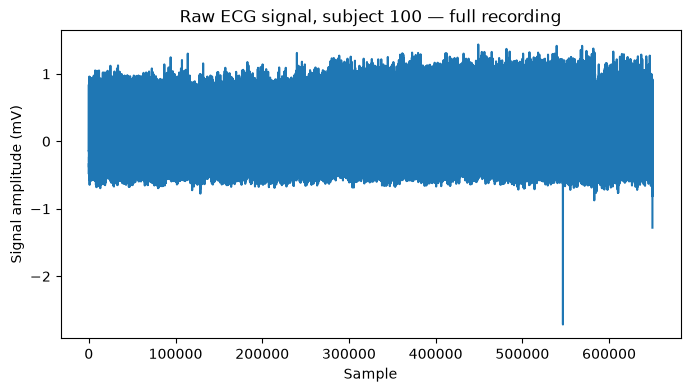

In [15]:
#  EXAMPLE — the whole 30-minute signal
# NOTE: this is one way to plot. Matplotlib is a powerful plotting library (you saw it last
# session); seaborn and plotly are popular alternatives.
# Documentation: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.html

plt.figure(figsize=(8, 4))
plt.plot(sig)
plt.xlabel('Sample')
plt.ylabel('Signal amplitude (mV)')
plt.title('Raw ECG signal, subject 100 — full recording')
plt.show()

# It looks like a solid block! 650,000 points are squeezed into a few centimetres of
# screen, so individual heartbeats are impossible to see. We can also spot some
# very large spikes - those are artifacts, not giant heartbeats.

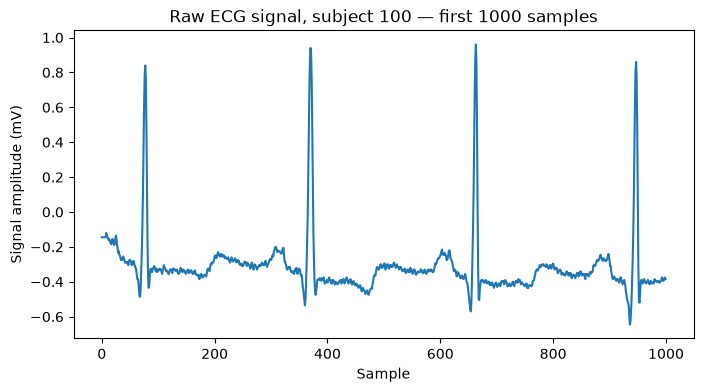

In [16]:
#  EXAMPLE — zooming in on the first 1000 samples (about 2.8 seconds)
# Now we can recognise individual heartbeats: each tall spike is one R peak.

plt.figure(figsize=(8, 4))
plt.plot(sig[0:1000])
plt.xlabel('Sample')
plt.ylabel('Signal amplitude (mV)')
plt.title('Raw ECG signal, subject 100 — first 1000 samples')
plt.show()

Notice that the x-axis shows **sample numbers**, not seconds. That is fine for a quick look, but a plot made for other people should show real time units.

### Your turn (A.3)

Plot the **first 3 seconds** of the signal **with the x-axis in seconds**.

*Hints:*
- First make the y-values: a slice of `sig` containing the first 3 seconds.
- Then make the x-values: `np.arange(n)` gives you `[0, 1, 2, ..., n-1]` (the sample numbers). How do you turn sample numbers into seconds? (Look at the jargon buster!)
- `plt.plot(x, y)` plots y against x. Don't forget the axis labels and a title.

In [17]:
# YOUR TURN — write your code here

# segment = ...                 # first 3 seconds of sig
# time_in_seconds = ...         # one time value (in s) for every sample in segment

# plt.figure(figsize=(8, 4))
# plt.plot(time_in_seconds, segment)
# ...

## A.4 Missing data (NaNs)

###  Concept

Real recordings have holes. Electrodes peel off, a smartwatch loses contact with the skin, batteries die, data transmission fails. When a measurement is missing, it is stored as **`NaN`** ("Not a Number").

NaNs have one crucial, annoying property: **they poison every calculation they touch.** Any ordinary arithmetic involving a NaN gives NaN:

- `5 + NaN` → `NaN`
- the mean of `[1, 2, NaN]` → `NaN`

So before computing anything, we must find the NaNs and decide what to do with them. Two tools help us:

- `np.isnan(x)` returns `True`/`False` for every sample ("is this one a NaN?").
- NaN-aware statistics like `np.nanmean(x)` compute the statistic **ignoring** the NaNs.

In [19]:
#  EXAMPLE — let's damage our signal on purpose
# NOTE: don't worry about how this function works - it is just our helper to add
# realistic missingness: scattered single missing samples + a few longer "dropout" gaps
# (as if the electrode briefly disconnected). You have already discussed in the module
# WHY missingness appears in real data.

def introduce_missingness(x, fs, p_nan=0.01, n_blocks=5, block_ms=(100, 300)):
    # Random single-point NaNs + several short dropout blocks.
    x = np.copy(x)
    n = len(x)

    # single-point NaNs
    idx = np.random.choice(n, size=int(p_nan * n), replace=False)
    x[idx] = np.nan

    # dropout blocks of NaNs
    for _ in range(n_blocks):
        dur = np.random.randint(int(block_ms[0] * fs / 1000), int(block_ms[1] * fs / 1000))
        start = np.random.randint(0, max(1, n - dur))
        x[start:start + dur] = np.nan

    return x

np.random.seed(42)   # "seeding" makes the randomness reproducible: everyone gets the same NaNs
sig_nan = introduce_missingness(sig, fs, p_nan=0.1)

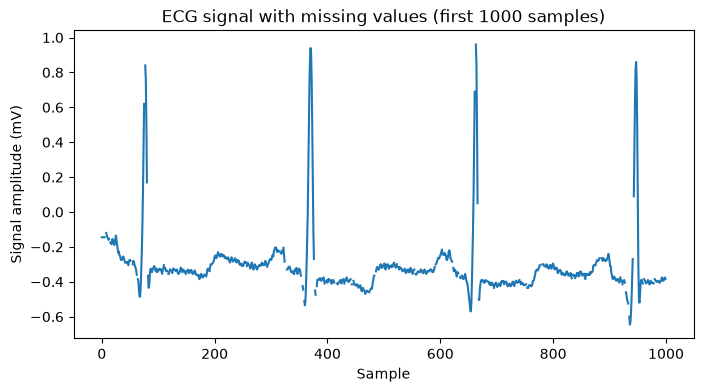

In [20]:
#  EXAMPLE — the damaged signal has visible gaps (matplotlib leaves holes where it meets NaNs)
plt.figure(figsize=(8, 4))
plt.plot(sig_nan[0:1000])
plt.xlabel('Sample')
plt.ylabel('Signal amplitude (mV)')
plt.title('ECG signal with missing values (first 1000 samples)')
plt.show()

In [21]:
#  EXAMPLE — watch the NaNs poison our statistics.
# Exactly the same code as in section A.2, but on the damaged signal:

print(f'Signal range: {np.min(sig_nan)} to {np.max(sig_nan)}')
print(f'Signal mean:  {np.mean(sig_nan):.2f}')
print(f'Signal std:   {np.std(sig_nan):.2f}')

# Everything is nan! A single missing value is enough to break ALL of these.

Signal range: nan to nan
Signal mean:  nan
Signal std:   nan


In [22]:
#  EXAMPLE — how many NaNs are there?
# np.isnan(sig_nan) gives an array of True/False. Summing it counts the Trues,
# because Python treats True as 1 and False as 0.
print(f'Total number of NaNs: {np.sum(np.isnan(sig_nan))}')

Total number of NaNs: 65385


### Your turn (A.4)

1. What **percentage** of the samples in `sig_nan` is missing? Print it with 2 decimal places. *Hint: (number of NaNs / total number of samples) × 100.*
2. Compute the mean and std of `sig_nan` while **ignoring** the NaNs. *Hint: look up `np.nanmean` and `np.nanstd` — numpy has a whole family of these "nan-proof" functions.*

In [23]:
# YOUR TURN — write your code here

# percentage_nan = ...
# print(f'Percentage of NaNs: ...')

# print(f'Mean (ignoring NaNs): ...')
# print(f'Std  (ignoring NaNs): ...')

## A.5 Handling missing data

###  Concept

Ignoring NaNs is fine for statistics, but for most analyses we need a complete signal with no holes. There are many strategies; today we focus on four simple, commonly used ones. Replacing missing values with estimates is called **imputation**.

<h4 style="color:#34495E;">1. Dropping NaN values</h4>
<div style="border-left:5px solid #85929E; padding:10px; margin-bottom:15px;">
Simply delete the missing samples. Quick and easy — but the signal becomes <strong>shorter</strong>, and the samples around a gap get glued together as if no time had passed between them. Timing information is distorted.
</div>

<h4 style="color:#34495E;">2. Mean / median imputation</h4>
<div style="border-left:5px solid #5DADE2; padding:10px; margin-bottom:15px;">
Replace every missing value with the <strong>mean</strong> (or <strong>median</strong>) of the whole signal. The length and timing are preserved, but every gap becomes a <strong>flat line at the average level</strong> — the imputed values ignore what was happening just before and after the gap.
</div>

<h4 style="color:#34495E;">3. Forward fill (last observation carried forward)</h4>
<div style="border-left:5px solid #48C9B0; padding:10px; margin-bottom:15px;">
Replace each missing value with the <strong>most recent valid value</strong>. The signal stays continuous (no sudden jumps into the gap), but long gaps become <strong>flat, "frozen" segments</strong> where the signal stops reflecting reality.
</div>

<h4 style="color:#34495E;">4. Rolling average (moving window imputation)</h4>
<div style="border-left:5px solid #F4D03F; padding:10px; margin-bottom:15px;">
Replace each missing value with the <strong>average of its neighbours</strong> within a small window. This uses the fact that in physiological signals, neighbouring samples are usually similar — often the most sensible of the four for short gaps.
</div>

Each method makes a different assumption about how your signal behaves over time. The best choice depends on your data and your research question — there is no universally "correct" answer.

*More advanced methods exist (e.g. the KNN imputer, which estimates missing values from the most similar samples in the dataset). They are typically designed for tabular data rather than continuous signals — if you are curious, see the [scikit-learn documentation](https://scikit-learn.org/stable/modules/impute.html).*

In [25]:
#  EXAMPLE — Method 1: dropping the NaNs

# 1. Find WHERE the NaNs are (their positions/indices, not the values themselves).
#    np.where returns the indices at which the condition is True.
nan_idx = np.where(np.isnan(sig_nan))
print(f'NaN locations: {nan_idx}')

print('\n')  # this just prints an empty line to separate the outputs

# 2. Keep only the samples that are NOT NaN:
sig_clean = sig_nan[~np.isnan(sig_nan)]
print(f'Clean signal: {sig_clean}')
print(f'Length of clean signal:    {len(sig_clean)}')
print(f'Length of original signal: {len(sig_nan)}')

NaN locations: (array([     6,      7,     14, ..., 649974, 649989, 649999],
      shape=(65385,)),)


Clean signal: [-0.145 -0.145 -0.145 ... -0.445 -0.675 -0.765]
Length of clean signal:    584615
Length of original signal: 650000


The expression `sig_nan[~np.isnan(sig_nan)]` looks cryptic at first. Here is what happens, step by step:

1. `np.isnan(sig_nan)` returns a True/False array of the same length as the signal: <span style="color:blue"><b>True</b></span> where a sample is NaN, <span style="color:red"><b>False</b></span> where it is a normal number.

2. `~` is the **NOT** operator in numpy: it flips every boolean. <span style="color:blue"><b>True</b></span> becomes <span style="color:red"><b>False</b></span> and vice versa. So `~np.isnan(sig_nan)` is True exactly where the sample is a **valid number**.

3. `sig_nan[ boolean_array ]` is **boolean indexing** (you saw it last session): it keeps only the elements where the boolean array is True.

Put together, the line says: **"keep all the values in `sig_nan` that are not NaN."**

In [26]:
#  By flipping the logic (no ~), you select the NaNs themselves instead:
nan_values = sig_nan[np.isnan(sig_nan)]
print(f'The NaNs themselves: {nan_values}')

The NaNs themselves: [nan nan nan ... nan nan nan]


In [27]:
#  EXAMPLE — Method 2: mean imputation
# np.where(condition, A, B) builds a new array that takes a value from A where the
# condition is True, and from B where it is False. So the line below reads:
# "where the signal is NaN use mean_val, everywhere else keep the original value".

def impute_mean(signal):
    mean_val = np.nanmean(signal)                        # mean, ignoring the NaNs
    return np.where(np.isnan(signal), mean_val, signal)  # swap NaNs for that mean

mean_imputation = impute_mean(sig_nan)
print(f'Signal after mean imputation: {mean_imputation}')
print(f'NaNs remaining: {np.sum(np.isnan(mean_imputation))}')

Signal after mean imputation: [-0.145     -0.145     -0.145     ... -0.675     -0.765     -0.3063015]
NaNs remaining: 0


### Your turn (A.5)

1. Write `impute_median(signal)`: exactly like `impute_mean`, but using the **median**. *Hint: numpy has `np.nanmedian`.* Apply it to `sig_nan` and store the result in `median_imputation`.
2. Complete the function `impute_forward(signal)` below (forward fill): walk through the signal from left to right, and whenever you meet a NaN, replace it with the previous value. Apply it to `sig_nan` and store the result in `fill_imputation`.

In [28]:
# YOUR TURN — write your code here

# 1. Median imputation:
# def impute_median(signal):
#     ...

# median_imputation = ...


# 2. Forward fill — complete the missing line:
# def impute_forward(signal):
#     filled = signal.copy()                # work on a copy, keep the original intact
#     for i in range(1, len(filled)):       # start at 1, so filled[i-1] always exists
#         if np.isnan(filled[i]):
#             filled[i] = ...               # <- replace the NaN with the previous value
#     return filled

# fill_imputation = ...

In [ ]:
#  EXAMPLE — Method 4: rolling average imputation
# For every NaN we look at a small neighbourhood around it (window samples on each
# side) and replace the NaN with the average of the valid values in that neighbourhood.

def impute_rolling(signal, window=3):
    filled = signal.copy()
    for i in range(len(signal)):
        if np.isnan(signal[i]):
            left = max(0, i - window)                  # don't fall off the start of the array
            right = min(len(signal), i + window + 1)   # don't fall off the end
            local_vals = signal[left:right]            # the neighbourhood
            filled[i] = np.nanmean(local_vals)         # average of its valid values
    return filled

rolling_imputation = impute_rolling(sig_nan)
print(f'NaNs remaining after rolling imputation: {np.sum(np.isnan(rolling_imputation))}')

# (If an entire neighbourhood is missing - a gap longer than the window - the NaN survives.
#  You could fix that by enlarging the window, or by running forward fill afterwards.)

/var/folders/6x/0spszywd2zl06zk2ky0y35gr0000gn/T/ipykernel_65437/3013248633.py:12: RuntimeWarning: Mean of empty slice
  filled[i] = np.nanmean(local_vals)         # average of its valid values


NaNs remaining after rolling imputation: 396


In [ ]:
#  EXAMPLE — now let's compare all methods side by side on the same stretch of signal:

fig, ax = plt.subplots(5, 1, figsize=(18, 12))
ax[0].plot(sig_nan[0:1000])
ax[0].set_ylabel('Amplitude (mV)')
ax[0].set_xticklabels([])
ax[0].set_title('ECG signal with NaNs')

ax[1].plot(sig_clean[0:1000])
ax[1].set_ylabel('Amplitude (mV)')
ax[1].set_xticklabels([])
ax[1].set_title('NaNs removed (dropped)')

ax[2].plot(mean_imputation[0:1000])
ax[2].set_ylabel('Amplitude (mV)')
ax[2].set_xticklabels([])
ax[2].set_title('Mean imputation')

ax[3].plot(fill_imputation[0:1000])
ax[3].set_ylabel('Amplitude (mV)')
ax[3].set_xticklabels([])
ax[3].set_title('Forward fill imputation')

ax[4].plot(rolling_imputation[0:1000])
ax[4].set_ylabel('Amplitude (mV)')
ax[4].set_title('Rolling average imputation')
plt.show()

####  What do you observe?

- Are there any **temporal differences** between the signals? (Compare where the heartbeats fall in the top panel vs. the "NaNs removed" panel.)
- Why do you see **flat segments / sudden plateaus** in the *mean imputation*? What causes them?
- Why does one of the peaks in the *forward fill* panel show a **flat top / dent**?
- Do you notice **any other differences** between the methods?

In [ ]:
 
# DISCUSSION NOTES (A.5) 
 
# - Dropping NaNs SHIFTS everything after a gap to the left: the heartbeats no longer
#   line up in time with the other panels. The more NaNs before a point, the bigger
#   the shift. This silently distorts all timing-based measurements (see A.11).

# - Mean imputation fills every gap with one constant value (the overall mean, ~ -0.3),
#   producing flat plateaus that jump abruptly to/from the surrounding signal.

# - Forward fill freezes the last value seen before the gap. When a gap starts on the
#   rising edge of an R peak, the peak gets a flat top (the "dent").

# - Rolling average produces the most natural-looking repairs for short gaps, but it
#   cannot fill gaps longer than its window.



## A.6 Smoothing with a moving average

###  Concept

Physiological signals carry fast, random wiggles — **noise** — from electrical interference, muscle activity, sensor movement. **Smoothing** reduces these wiggles so the underlying pattern (the heartbeats) stands out.

The simplest smoother is the **moving average**: slide a small "window" along the signal and replace each sample with the average of the samples inside the window.

$$y[n] = \frac{1}{k}\sum_{j=-\frac{k-1}{2}}^{\frac{k-1}{2}} x[n+j]$$

Don't let the formula scare you — in words it says exactly this:

1. take a window **k samples wide**,
2. slide it across the signal,
3. at each position, output the **average of the samples inside the window**.

Why does averaging remove noise? Noise is random: at any instant it is just as likely to push the signal up as down. Average a handful of neighbouring samples and those random pushes largely **cancel out** — while the true signal, which changes slowly from sample to sample, survives.

**The catch:** the window size `k` is a trade-off. Small window → noise remains. Large window → you start averaging *away the signal itself*: the sharp R peaks become smaller and rounder. Choosing `k` is a judgement call.

In [33]:
#  EXAMPLE — a moving average function
# From here on we work with sig_clean (the NaN-free signal from A.5).

def moving_average(signal, k):
    # Near the edges of the signal the window would stick out of the array, so we
    # "pad" the signal with zeros on both sides first. The padding adds k-1 extra
    # samples in total, which keeps the output exactly as long as the input.
    # (Side effect: the first/last few output samples are dragged towards 0.)
    if k < 2:
        print('k must be 2 or greater')
        return signal

    pad_left = k // 2            # // is integer division: 7 // 2 = 3
    pad_right = k - 1 - pad_left
    padded = np.concatenate((np.zeros(pad_left), signal, np.zeros(pad_right)))

    kernel = np.ones(k) / k      # k copies of 1/k: multiplying + summing = averaging
    return np.convolve(padded, kernel, mode='valid')   # slide the window along the signal

smooth_sig = moving_average(sig_clean, 10)
print(f'Input length:  {len(sig_clean)}')
print(f'Output length: {len(smooth_sig)}   (same = good!)')

Input length:  584615
Output length: 584615   (same = good!)


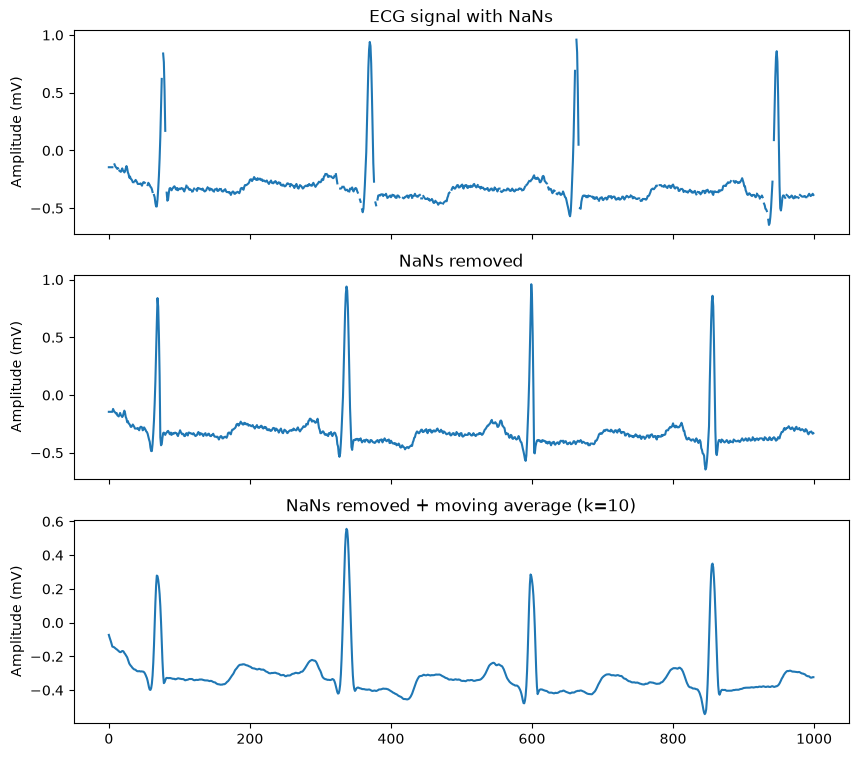

In [34]:
#  EXAMPLE — before vs. after smoothing

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
ax[0].plot(sig_nan[0:1000])
ax[0].set_ylabel('Amplitude (mV)')
ax[0].set_xticklabels([])
ax[0].set_title('ECG signal with NaNs')

ax[1].plot(sig_clean[0:1000])
ax[1].set_ylabel('Amplitude (mV)')
ax[1].set_xticklabels([])
ax[1].set_title('NaNs removed')

ax[2].plot(smooth_sig[0:1000])
ax[2].set_ylabel('Amplitude (mV)')
ax[2].set_title('NaNs removed + moving average (k=10)')
plt.show()

### Your turn (A.6)

How does the window size change the result? Smooth `sig_clean` with **k = 3, 10, 30 and 100** and plot the first 1000 samples of each result in its own subplot (one on top of the other, like the figure above).

*Hints:*
- Put the window sizes in a list: `kernels = [3, 10, 30, 100]`.
- Loop over them. `enumerate(kernels)` gives you both a counter `i` (for choosing the subplot `ax[i]`) and the value `k`.
- Give each subplot a title saying which `k` it shows (f-strings!).

In [35]:
# YOUR TURN — write your code here

# kernels = [3, 10, 30, 100]
# fig, ax = plt.subplots(len(kernels), 1, figsize=(10, 12))
# for i, k in enumerate(kernels):
#     ...

In a real analysis we would now compare the window sizes carefully and justify our choice. For the sake of this exercise we will simply continue with **k = 10** — big enough to calm the noise, small enough to keep the R peaks tall.

In [37]:
sig_smooth = moving_average(sig_clean, 10)

## A.7 Normalisation (z-scoring)

###  Concept

Different sensors, or even the same sensor on different days, record with different amplitude ranges. One ECG might swing between −2 and +2 mV, another between −0.5 and +0.5 mV, even though both hearts behave the same. To compare signals fairly, we put them on a **common scale**.

The standard recipe is the **z-score**: subtract the mean, then divide by the standard deviation.

$$y[n] = \frac{x[n] - \text{mean}(x)}{\text{std}(x)}$$

After this transformation every signal has **mean 0** and **standard deviation 1**, whatever units or amplitude it started with. The *shape* of the signal is untouched — only the scale of the y-axis changes. (You will meet z-scores again and again: in statistics, machine learning, neuroimaging...)

In [38]:
#  EXAMPLE — z-scoring a tiny array by hand, so you can follow every number
tiny = np.array([2.0, 4.0, 6.0, 8.0, 10.0])

tiny_mean = np.mean(tiny)   # 6.0
tiny_std = np.std(tiny)     # ~2.83

tiny_normalised = (tiny - tiny_mean) / tiny_std

print(f'Original:      {tiny}')
print(f'Mean: {tiny_mean},  Std: {tiny_std:.2f}')
print(f'Normalised:    {np.round(tiny_normalised, 2)}')
print(f'New mean: {np.mean(tiny_normalised):.2f},  New std: {np.std(tiny_normalised):.2f}')

# Values below the original mean became negative, values above it positive,
# and a value of +1 now means "one standard deviation above average".

Original:      [ 2.  4.  6.  8. 10.]
Mean: 6.0,  Std: 2.83
Normalised:    [-1.41 -0.71  0.    0.71  1.41]
New mean: 0.00,  New std: 1.00


### Your turn (A.7)

1. Write a function `normalise(signal)` that z-scores a signal (use the formula above).
2. Apply it to `sig_clean` and store the result in `normalised_sig`.
3. Check your work: print the mean and std of `normalised_sig`. What should they be?
4. Plot the first 1000 samples of `sig_clean` and `normalised_sig` in two subplots. Compare the two y-axes.

In [39]:
# YOUR TURN — write your code here

# def normalise(signal):
#     ...

# normalised_sig = ...

## A.8 Filtering: removing unwanted frequencies

###  Concept

Think of a signal as a **smoothie**: a mixture of ingredients blended together. The ingredients of a signal are oscillations of different speeds — different **frequencies**, measured in Hz (cycles per second). Our ECG recording contains, mixed together:

- **Very slow drifts (below ~0.5 Hz)** — the whole baseline slowly wandering up and down, caused by breathing and electrode movement. Not heart activity.
- **The heartbeats themselves (roughly 0.5–40 Hz)** — the rhythm is about 1 beat per second, and the sharp QRS spike needs faster ingredients (tens of Hz) to keep its pointy shape.
- **Fast noise (above ~40 Hz)** — muscle activity and electrical interference from the mains power (50 Hz in the UK, 60 Hz in the US, where this dataset was recorded).

A **filter** is a sieve for frequencies:

| Filter | What passes through |
|:---|:---|
| **Low-pass** | only the slow ingredients (removes fast noise) |
| **High-pass** | only the fast ingredients (removes slow drift) |
| **Band-pass** | only a middle range — a low-pass and a high-pass combined |

For ECG we band-pass between about **0.5 and 40 Hz**: throw away the baseline drift *and* the fast noise, keep the heartbeats. (We will use 0.5–30 Hz today, a slightly stricter but common choice.)

**Three practical things to know** (no maths required — `scipy` does all of it for us):

1. **The Nyquist frequency.** A digital signal sampled at `fs` can only represent frequencies up to `fs / 2` — you need at least 2 samples per cycle to see a frequency at all. `fs / 2` is called the Nyquist frequency, and scipy asks us to express our cutoff frequencies as a *fraction* of it. Sampling too slowly for the frequencies present causes **aliasing**: high frequencies (fast wiggles) masquerade as slow ones (more on this in A.9).
2. **The Butterworth filter** is a classic filter design, prized for leaving the frequencies it keeps almost perfectly untouched ("maximally flat"). Its **order** controls how sharply it cuts: a low order lets frequencies near the cutoff partially leak through; a higher order cuts more abruptly. A 4th-order Butterworth is a very common practical choice. The image below shows how the cutoff gets steeper as the order grows.
3. **`filtfilt`** runs the filter forwards and then backwards over the signal. This trick ("zero-phase filtering") guarantees that the filtering does not shift your peaks in time — which matters a lot when the *timing* of R peaks is exactly what we want to measure.


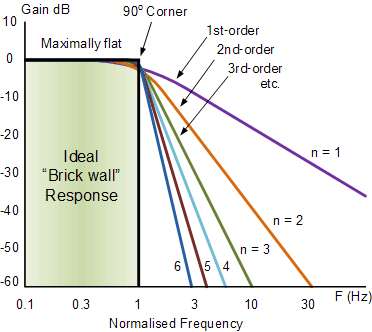

*Gain of a Butterworth low-pass filter for different orders: the higher the order, the sharper the cutoff.*

In [ ]:
#  EXAMPLE — the IDEA of a band-pass, built from two moving averages
# We can fake a band-pass with tools we already have:
#   - a NARROW moving average keeps everything except the fastest noise (a low-pass)
#   - a WIDE moving average keeps only the slow drift
#   - subtracting the slow drift from the low-passed signal removes it (a high-pass)
# What survives is the "middle" - a (crude!) band-pass.

def simple_bandpass(signal, narrow_window=3, wide_window=30):
    without_fast_noise = moving_average(signal, narrow_window)  # low-pass
    slow_drift = moving_average(signal, wide_window)            # the slow ingredients only
    return without_fast_noise - slow_drift                      # subtract the drift

simple_bandpassed_sig = simple_bandpass(sig_clean)

In [42]:
#  EXAMPLE — the real thing, with scipy
from scipy.signal import butter, filtfilt

def bandpass_filter(signal, fs, low_cutoff=0.5, high_cutoff=30, order=4):
    nyquist = 0.5 * fs                   # the highest frequency this signal can represent
    low = low_cutoff / nyquist           # scipy wants cutoffs as fractions of Nyquist
    high = high_cutoff / nyquist
    b, a = butter(order, [low, high], btype='band')   # design the filter...
    return filtfilt(b, a, signal)                     # ...and apply it (zero-phase)

bandpass_sig = bandpass_filter(sig_clean, fs)

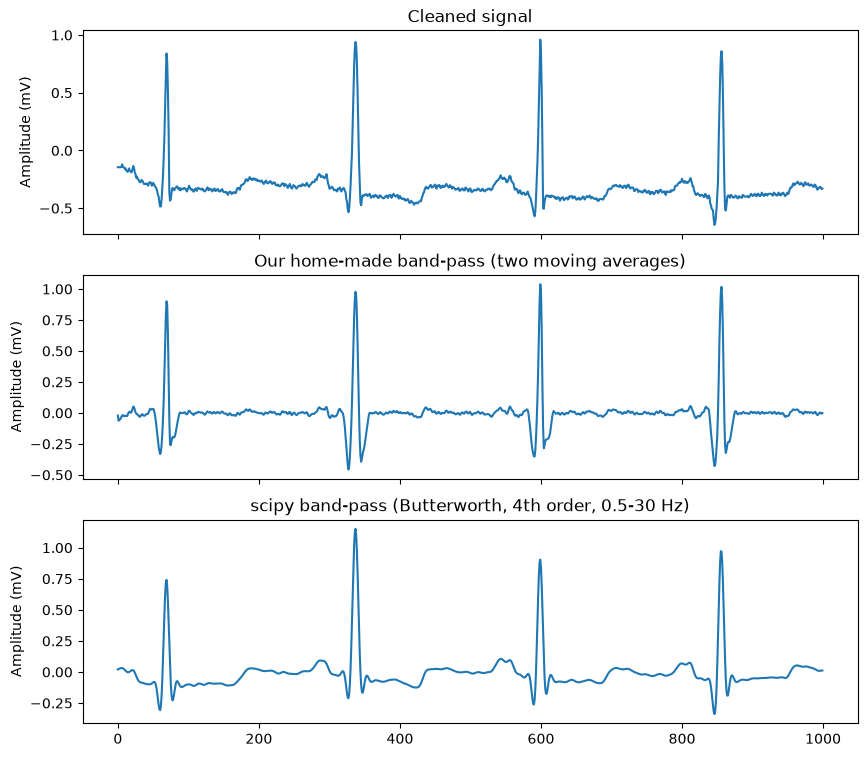

In [43]:
#  EXAMPLE — compare the three versions

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
ax[0].plot(sig_clean[0:1000])
ax[0].set_ylabel('Amplitude (mV)')
ax[0].set_xticklabels([])
ax[0].set_title('Cleaned signal')

ax[1].plot(simple_bandpassed_sig[0:1000])
ax[1].set_ylabel('Amplitude (mV)')
ax[1].set_xticklabels([])
ax[1].set_title('Our home-made band-pass (two moving averages)')

ax[2].plot(bandpass_sig[0:1000])
ax[2].set_ylabel('Amplitude (mV)')
ax[2].set_title('scipy band-pass (Butterworth, 4th order, 0.5-30 Hz)')
plt.show()

**Why do the fake filter and the real one give different results?** Our fake filter was never actually told which frequencies to keep — we just picked two window sizes and got whatever cut-off those happen to produce, with a very blurry boundary between “kept” and “removed”. The scipy filter is a precision sieve: we tell it exactly “keep 0.5 to 30 Hz” and it does that cleanly. So the two aren’t just better and worse versions of the same thing — they’re actually keeping different parts of the signal.

####  What do you observe?

- Both filtered signals now oscillate around **0** — where did the baseline go?
- Are there **temporal differences** between the signals? Do the R peaks still line up?
- What differences do you notice between our home-made filter and the scipy one?

**Where did the baseline go?** The baseline is the slow up-and-down drift of the whole signal. A band-pass filter throws away the slowest frequencies, and the baseline is the slowest one. Take it away and there’s nothing left to hold the signal up or down, so it naturally settles around zero.

**Do the R peaks still line up in time?** Yes. Neither filter pushes the signal left or right. The moving average looks at an equal number of neighbours on both sides of each point, so it’s balanced. The scipy filter would normally delay things slightly, but filtfilt runs it forwards and then backwards, so any delay from the first pass is exactly cancelled by the second. That matters because our whole analysis is about when the peaks happen — a filter that shifted them would quietly corrupt every heart-rate number we compute later.

**What differences can you actually see between the two?** Three things. The real filter keeps the small round waves around each spike (the P and T waves); the fake one mostly erases them, leaving just the spikes. The fake filter’s output is also smaller overall, because its crude subtraction accidentally removes some of the real signal along with the drift. And the fake one still looks a bit fuzzy, because a 3-sample average barely touches fast noise, while the scipy filter trims it properly. In short: the scipy result looks like a cleaner version of the original heartbeat; the fake one looks like a rough sketch of just the spikes.

### Your turn (A.8)

How does the **order** of the Butterworth filter change the result? Filter `sig_clean` with orders **1, 2, 4 and 5** (keep the default cutoffs) and plot the first 1000 samples of each in its own subplot, with a title showing the order.

Afterwards, also **try changing the cutoff frequencies** (e.g. make the band very narrow, like 5–10 Hz) and see what happens to the heartbeat shape.

In [44]:
# YOUR TURN — write your code here

# butter_orders = [1, 2, 4, 5]
# fig, ax = plt.subplots(len(butter_orders), 1, figsize=(10, 10))
# for i, order in enumerate(butter_orders):
#     ...

####  What do you observe?

- What happens as you increase the filter's order? Does the plot eventually go blank?

**Hint:** your computer represents numbers with limited precision. For high orders (combined with cutoffs very close to 0), the filter's internal coefficients become so extreme that the computer can no longer calculate with them accurately. The maths becomes unstable (a bit like dividing by nearly zero), the output turns into NaNs, and the plot looks empty. This is a *numerical* problem, not a conceptual one — one more reason the modest 4th order is such a popular choice.

## A.9 Resampling / downsampling

###  Concept

**Downsampling** means keeping fewer samples per second. Why would we throw data away?

- To **shrink** huge files and speed up computations.
- To **match** signals recorded at different rates (e.g. an ECG at 360 Hz and an accelerometer at 100 Hz) before comparing them.

The naive way is to keep every *n*-th sample and discard the rest. The danger is **aliasing**: if the remaining samples are too sparse for the high frequencies in the signal, those high frequencies *disguise themselves as slow ones*. You have seen aliasing in everyday life: helicopter blades or car wheels in a video that seem to rotate slowly, or even backwards — the camera's frame rate is too slow for the true rotation. (This is the Nyquist rule from A.8 in action: after downsampling, the new `fs/2` must still be above the fastest frequency you care about.)

`scipy.signal.resample` is the safer tool: it works with the frequency content of the signal to reduce the sample count with as little distortion as possible.

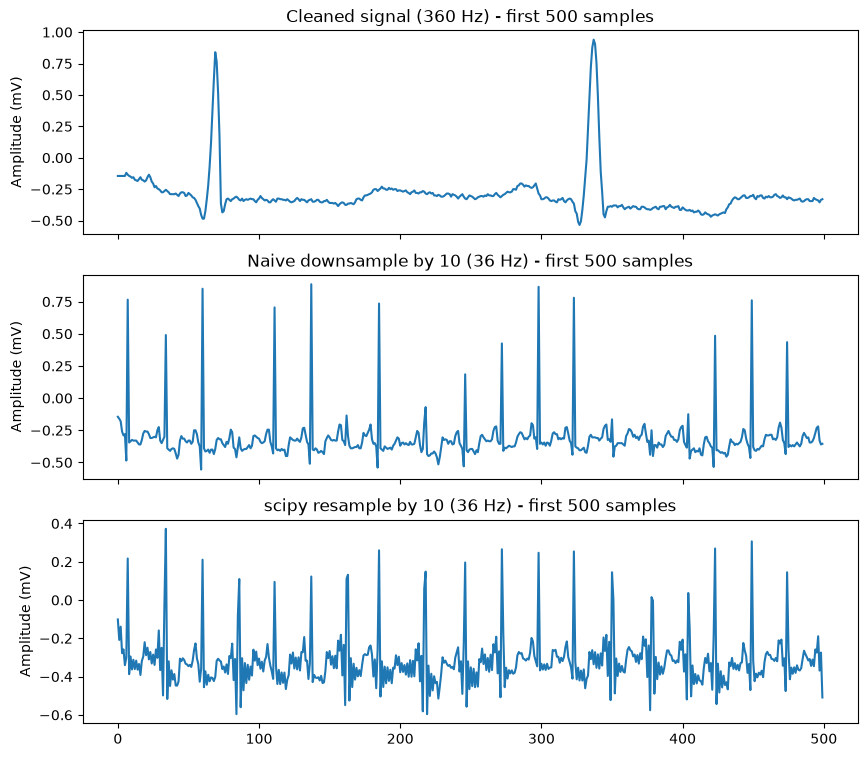

In [46]:
#  EXAMPLE — naive downsampling vs. scipy resample

# Naive: keep every n-th sample. In slice notation signal[::n] means
# "from start to end, in steps of n".
def naive_downsample(signal, n):
    return signal[::n]

# Safer: scipy
from scipy.signal import resample

def resample_signal(signal, new_length):
    return resample(signal, new_length)

naive_downsampled_sig = naive_downsample(sig_clean, 10)              # 10x fewer samples
resampled_sig = resample_signal(sig_clean, len(sig_clean) // 10)     # also 10x fewer

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
ax[0].plot(sig_clean[0:500])
ax[0].set_ylabel('Amplitude (mV)')
ax[0].set_xticklabels([])
ax[0].set_title('Cleaned signal (360 Hz) - first 500 samples')

ax[1].plot(naive_downsampled_sig[0:500])
ax[1].set_ylabel('Amplitude (mV)')
ax[1].set_xticklabels([])
ax[1].set_title('Naive downsample by 10 (36 Hz) - first 500 samples')

ax[2].plot(resampled_sig[0:500])
ax[2].set_ylabel('Amplitude (mV)')
ax[2].set_title('scipy resample by 10 (36 Hz) - first 500 samples')
plt.show()

# Note: the panels now cover different amounts of TIME. 500 samples at 360 Hz is
# ~1.4 seconds; 500 samples at 36 Hz is ~14 seconds - that's why the lower panels
# show many more heartbeats.

####  What do you observe?

- How much **time** does each panel cover? (Careful — the x-axis counts samples, and the sampling rates differ!)
- Compare the heartbeat shapes: what has happened to the R peaks after downsampling? Why could this be a problem?

### Your turn (A.9)

Downsample `sig_clean` naively by a factor of **50** and plot the first 200 samples.

- What is the new sampling frequency?
- Can you still recognise individual heartbeats? Relate what you see to the Nyquist rule from A.8.

In [47]:
# YOUR TURN — write your code here

# downsampled_50 = ...
# new_fs = ...

## A.10 Finding the heartbeats: peak detection

###  Concept

To measure heart rate we need to know **when each R peak occurs**. An R peak is a **local maximum**: a sample that is **larger than both of its neighbours**.

Tiny example — where are the local maxima of `[1, 3, 2, 5, 4]`?

- position 1 (value 3): bigger than 1 on its left and 2 on its right → **peak** ✔
- position 3 (value 5): bigger than 2 and 4 → **peak** ✔

One problem: the ECG is full of *small* local maxima too — the P waves, the T waves, leftover noise. A simple but effective fix for this clean recording: keep only the peaks whose amplitude is **above a threshold**, because the R peaks tower above everything else. (Real-world R-peak detectors are more sophisticated — you will meet proper signal processing later in the programme.)

In [ ]:
# First, let's cut our smoothed signal down to its first 3000 samples (~8 seconds),
# purely so the plots are easy to read.
sig_smooth = sig_smooth[:3000]

Number of local maxima found: 47774


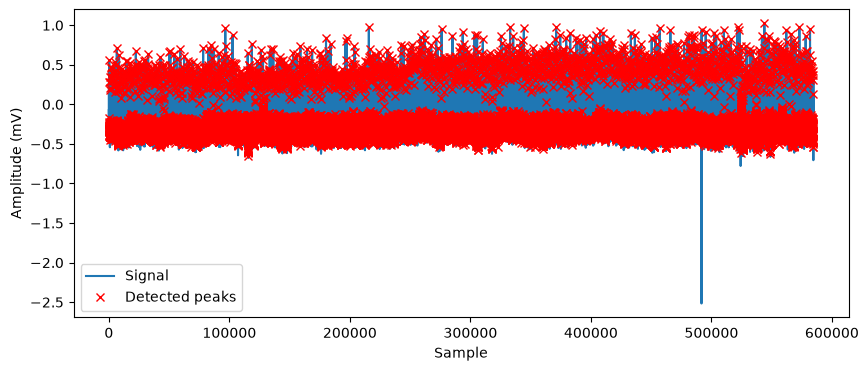

In [ ]:
# EXAMPLE — find ALL local maxima (no quality criteria yet)
from scipy.signal import find_peaks

peaks, properties = find_peaks(sig_smooth)   # no options: every single local maximum
print(f'Number of local maxima found: {len(peaks)}')

plt.figure(figsize=(10, 4))
plt.plot(sig_smooth, label='Signal')
# to get the HEIGHT of each peak, we index the signal with the peak positions: signal[peaks]
plt.plot(peaks, sig_smooth[peaks], 'rx', label='Detected peaks')
plt.xlabel('Sample')
plt.ylabel('Amplitude (mV)')
plt.legend()
plt.show()

# Far too many crosses! P waves, T waves and small noise bumps are local maxima too.
# In ~8 seconds we expect roughly 8-10 heartbeats, not hundreds of peaks.

### Your turn (A.10)

Write a function `keep_tall_peaks(signal, peaks, threshold)` that keeps only the peaks whose amplitude is **above** the threshold. Use a threshold of **0.0 mV** — in this smoothed recording, only the R peaks reach above 0.

*Hints (this is boolean indexing again, like in A.5):*
1. Get the amplitude of the signal at each peak: `signal[peaks]`.
2. Build a boolean mask: which of those amplitudes are `> threshold`?
3. Use the mask to index `peaks`.

Then re-plot the signal with only the surviving peaks. Count them — does the number look like a plausible number of heartbeats for ~8 seconds?

In [ ]:
# YOUR TURN — write your code here

# r_peaks, _ = find_peaks( ... )
# print(f'Peaks remaining: ...')
# ... (plot)

## A.11 From signal to features

###  Concept

A **feature** is a single number that summarises something meaningful about a signal. Doctors do this instinctively: they compress an entire examination into a handful of vital signs ("HR 72, BP 120/80"). We will do the same with code — compress ~3000 samples into a small set of informative numbers that could later feed a machine learning model.

The star of ECG analysis is the **RR interval**: the time between two consecutive R peaks, i.e. the duration of one heartbeat. From it comes the most famous feature of all:

$$\text{heart rate (beats/min)} = \frac{60}{\text{RR interval (s)}}$$

If beats are 0.8 s apart, the heart completes $60 / 0.8 = 75$ beats per minute.

One subtlety: our peak positions are in **samples**, not seconds. As always, dividing by `fs` converts samples → seconds.

*(Note: we are not worrying yet about how well these features would work together in a machine learning model — that is for Module 5.)*

In [ ]:
#  EXAMPLE — RR intervals, computed with a loop

def rr_intervals(peaks, sampling_freq):
    all_times = []
    for r in range(len(peaks) - 1):          # for each PAIR of consecutive peaks...
        samples_between = peaks[r + 1] - peaks[r]       # distance in samples
        time_between = samples_between / sampling_freq  # convert to seconds
        all_times.append(time_between)

    return np.mean(all_times), np.median(all_times)

rr_mean, rr_median = rr_intervals(r_peaks, fs)
print(f'Mean RR interval:   {rr_mean:.3f} s')
print(f'Median RR interval: {rr_median:.3f} s')

### Your turn (A.11a)

The loop works, but numpy can do this in a single line. Write `rr_intervals_efficient(peaks, sampling_freq)` that returns exactly the same two numbers without any loop.

*Hint: numpy provides a function that calculates the difference between consecutive elements of an array. Its name is very guessable... ([documentation](https://numpy.org/doc/stable/reference/generated/numpy.diff.html))*

In [56]:
# YOUR TURN — write your code here

# def rr_intervals_efficient(peaks, sampling_freq):
#     ...
#     return ...

# Check that it gives the same result as the loop version!

> Back in A.5 we handled the missing data by *dropping* the NaNs. That glued the samples around each gap together, silently shortening the time between some peaks. Every RR interval that spans a former gap is therefore slightly **underestimated** — and so is every feature built on it. This is a perfect example of why the choice of imputation method matters: it propagates all the way into your final features.

In [ ]:
#  EXAMPLE — amplitude features: how TALL are the R peaks on average?

def peak_magnitude(signal, peaks):
    mag_mean = np.mean(signal[peaks])
    mag_median = np.median(signal[peaks])
    return mag_mean, mag_median

rr_mag_mean, rr_mag_median = peak_magnitude(sig_smooth, r_peaks)
print(f'Mean R-peak amplitude:   {rr_mag_mean:.3f} mV')
print(f'Median R-peak amplitude: {rr_mag_median:.3f} mV')

### Your turn (A.11b)

Write `peak_magnitude_std(signal, peaks)` returning the **standard deviation** of the R-peak amplitudes, and apply it. A healthy, stable recording should have quite similar peak heights — i.e. a *small* std.

In [60]:
# YOUR TURN — write your code here

# def peak_magnitude_std(signal, peaks):
#     ...

### Your turn (A.11c)

Write `peak_frequency(signal, peaks, sampling_freq)` that returns two numbers:

1. `total_peaks` — the total **number** of R peaks, and
2. `rr_freq` — how many peaks occur **per second** on average.

*Hint for 2: (number of peaks) ÷ (duration of the signal in seconds). You know how to get the duration from `len(signal)` and `fs`.*

Sanity check: peaks-per-second × 60 should be roughly a human heart rate (60–100 beats/min at rest).

In [62]:
# YOUR TURN — write your code here

# def peak_frequency(signal, peaks, sampling_freq):
#     ...
#     return rr_freq, total_peaks

### Your turn (A.11d) — heart rate

Fill in the blanks (`...`) in the two functions below.

- `calculate_average_hr` computes ONE heart rate for the whole signal, from the **mean** RR interval (use the formula from the concept box).
- `calculate_instant_hr` computes a heart rate from **each individual** RR interval ("instantaneous" heart rate, beat by beat), then returns the mean of those.

If every beat were equally long, the two would be identical. In reality the RR intervals vary from beat to beat (this variation is itself clinically interesting — "heart rate variability"), so the two numbers come out slightly different.

In [64]:
# YOUR TURN — fill in the blanks (replace the ... parts)

# def calculate_average_hr(peaks, sampling_freq):
#     mean_rr, _ = rr_intervals_efficient(peaks, sampling_freq)
#     hr = ...                        # <- 60 divided by the mean RR interval
#     return hr

# def calculate_instant_hr(peaks, sampling_freq):
#     hrs_list = []
#     for i in range(1, len(peaks)):  # start at 1: each beat needs a PREVIOUS beat
#         rr = ...                    # <- RR interval between peak i-1 and peak i, in seconds
#         hr = ...                    # <- heart rate for this single beat
#         hrs_list.append(hr)
#     return np.mean(hrs_list)

# mean_hr = ...
# instant_hr = ...

## A.12 Putting it all together: a feature table

###  Concept

In a real study you have many participants, and for each one you compute the same set of features. The natural way to organise this is a **table: one row per participant, one column per feature** — exactly what a pandas DataFrame is for (and exactly the format machine learning models expect).

Recipe for one row:
1. Put the features into a **dictionary**: `{'feature_name': value, ...}`.
2. `pd.DataFrame([row_dict])` turns that dictionary into a one-row table.
3. `pd.concat` stacks the rows of several participants into one big table.

In [ ]:
#  EXAMPLE — one row for our subject

features = {
    'subject_id': 'S-100',
    'mean_RR_interval': rr_mean,
    'median_RR_interval': rr_median,
    'mean_RR_amplitude': rr_mag_mean,
    'median_RR_amplitude': rr_mag_median,
    'std_RR_amplitude': rr_mag_std,
    'RR_frequency': rr_freq,
    'total_RR_peaks': total_peaks,
    'mean_heart_rate': mean_hr,
    'instant_heart_rate': instant_hr,
}

df = pd.DataFrame([features])   # note the [ ]: a list containing one dictionary = one row
df

### Your turn (A.12) — the full pipeline

Now the payoff for writing functions all along: processing a **new** subject is just calling them in order. Complete the function below so that it runs our whole pipeline for a list of subjects and stacks everything into one table. (We skip the NaN-handling step here: we will pretend the downloaded signals are complete, and only smooth them.)

The steps for each subject are already written as comments — replace the `...` parts. Then run it for subjects `"100", "101", "105", "106", "107", "109"` (this downloads data, so it takes a little while).

In [ ]:
# YOUR TURN — fill in the blanks

# def extract_features_for_all(subject_ids):
#     df_all = pd.DataFrame()                       # start with an empty table
#
#     for subject_id in subject_ids:
#         # 1. download
#         sig, fs = download_ecg_data(subject_id)
#
#         # 2. preprocess: smooth with a moving average (k=10), keep first 6000 samples
#         smooth = ...
#         smooth = smooth[:6000]
#
#         # 3. detect R peaks: local maxima taller than 0 mV
#         peaks, _ = find_peaks( ... )
#
#         # 4. compute the features (reuse our functions!)
#         rr_mean, rr_median = ...
#         rr_mag_mean, rr_mag_median = ...
#         rr_freq, total_peaks = ...
#
#         features = {
#             'subject_id': f'S-{subject_id}',
#             'mean_RR_interval': rr_mean,
#             ...
#         }
#
#         # 5. one row for this subject, stacked onto the big table
#         df = pd.DataFrame([features])
#         df_all = pd.concat([df_all, df], ignore_index=True)
#
#     return df_all

# subject_ids = ["100", "101", "105", "106", "107", "109"]
# df_all = extract_features_for_all(subject_ids)
# df_all

### Recap

You have just built a complete ECG feature-extraction pipeline:

1. **Load** a signal and understand its timing (`fs`, duration).
2. **Inspect** it with statistics and plots.
3. **Handle missing data** (drop / mean / median / forward fill / rolling average).
4. **Clean** it (smoothing, normalisation, band-pass filtering, downsampling).
5. **Detect events** (R peaks via local maxima + a threshold).
6. **Extract features** (RR intervals, amplitudes, heart rate).
7. **Organise** everything into a tidy table, for many subjects.

In Part B we apply the same workflow to a very different signal: wrist accelerometer data from a Parkinson's disease study — this time stored in a pandas DataFrame from the start.

---
# Part B — Wearable accelerometer data

### What does an accelerometer measure?

An **accelerometer** measures acceleration — how quickly velocity changes — along one or more axes (typically **x**, **y** and **z**). In a smartwatch, it detects steps, gestures, and even subtle tremors.

Two things to keep in mind:

- The readings are in **g units**, multiples of the acceleration of gravity. An accelerometer lying still does *not* read zero — it senses gravity itself, so a motionless device reads 1 g along whichever axis points "down".
- An accelerometer alone cannot distinguish moving in a straight line from rotating. That is why wearables also carry a **gyroscope**, which measures rotation speed. Together they give a complete picture of motion. (Today we only use the accelerometer.)

In neuroscience and physiology, wrist-, chest- or lumbar-worn accelerometers are widely used to infer activity patterns, sleep cycles and motor behaviours — a continuous, non-invasive window into how people move.

### The PADS dataset

We will use data from the [**Parkinson's Disease Smartwatch (PADS) dataset**](https://physionet.org/content/parkinsons-disease-smartwatch/1.0.0/) on PhysioNet, collected in a clinical study of digital biomarkers for Parkinson's disease (PD):

- Participants include **PD patients, people with similar movement disorders, and healthy controls**.
- Each participant wore **two smartwatches, one on each wrist**, and performed **11 guided movement tasks** of 10–20 seconds each, designed by neurologists to bring out movement-related symptoms.
- The watches recorded acceleration (in g) at a sampling rate of about **100 Hz**.
- The full dataset also contains demographics, medical history and non-motor symptom questionnaires.

For this class we use a simplified extract: a single CSV with the accelerometer data of **10 participants**. We will work through the same pipeline as in Part A — load → inspect → clean → window → features — but this time the data lives in a **pandas DataFrame** instead of a bare numpy array.

## B.1 Loading and exploring a tabular time series

###  Concept

In Part A our signal was a single numpy array. Real study data usually arrives as a **table**: each row is one sample, and extra columns tell you *whose* sample it is, *which* task was being performed, *when* it was measured, and so on. Pandas is built for this.

The first-contact toolkit for any new DataFrame (you met these last session):

- `df` or `df.head()` — look at it!
- `df.shape` — how many rows and columns?
- `df['column'].describe()` — summary of one column.
- `df['column'].value_counts()` — how often does each unique value occur?
- `df[df['column'] == value]` — boolean filtering: keep only the matching rows.

In [68]:
# Imports again, in case you are starting the notebook from here after restarting the kernel:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#  EXAMPLE — load the data 
original_data = pd.read_csv("/data/pads10_accelerometer_data.csv")
original_data

,t_s,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,subject_id,task,wrist
0,0.000000,-0.003958,0.002360,1.746120e-03,-0.015492,0.005616,0.001034,1,Relaxed,LeftWrist
1,0.009903,-0.004005,0.002259,8.355394e-04,-0.012276,0.005605,-0.003218,1,Relaxed,LeftWrist
2,0.019901,0.000833,0.002225,9.437218e-04,-0.009051,0.002432,-0.002137,1,Relaxed,LeftWrist
3,0.029907,-0.000191,0.004109,4.783000e-07,-0.008911,0.002154,-0.000931,1,Relaxed,LeftWrist
4,0.039984,0.001769,0.004064,-1.902400e-03,-0.007830,0.000034,0.000145,1,Relaxed,LeftWrist
...,...,...,...,...,...,...,...,...,...,...
286715,287.348301,-0.010799,-0.014519,2.704642e-02,-0.008807,-0.047071,-0.075114,10,Entrainment,RightWrist
286716,287.358366,-0.004689,-0.016576,2.908126e-02,0.005117,-0.052290,-0.080429,10,Entrainment,RightWrist
286717,287.368694,-0.006375,-0.015545,2.615968e-02,0.029638,-0.049946,-0.079373,10,Entrainment,RightWrist
286718,287.378754,-0.002194,-0.014229,2.901689e-02,0.053075,-0.045462,-0.074068,10,Entrainment,RightWrist


<div style="border-left:5px solid #5DADE2; padding:15px;">

<h4>What the columns mean</h4>

| **Column** | **Description** |
|:---|:---|
| **`subject_id`** | Unique identification number of each participant |
| **`wrist`** | Which wrist the watch was on (`LeftWrist` / `RightWrist`) |
| **`task`** | Which of the 11 movement tasks was being performed |
| **`t_s`** | Timestamp in **seconds** since the start of the recording |
| **`Acc_X`**, **`Acc_Y`**, **`Acc_Z`** | Acceleration along the x, y and z axes, in **g units** |
</div>

In [70]:
#  EXAMPLE — first few rows only:
original_data.head()

,t_s,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,subject_id,task,wrist
0,0.000000,-0.003958,0.002360,1.746120e-03,-0.015492,0.005616,0.001034,1,Relaxed,LeftWrist
1,0.009903,-0.004005,0.002259,8.355394e-04,-0.012276,0.005605,-0.003218,1,Relaxed,LeftWrist
2,0.019901,0.000833,0.002225,9.437218e-04,-0.009051,0.002432,-0.002137,1,Relaxed,LeftWrist
3,0.029907,-0.000191,0.004109,4.783000e-07,-0.008911,0.002154,-0.000931,1,Relaxed,LeftWrist
4,0.039984,0.001769,0.004064,-1.902400e-03,-0.007830,0.000034,0.000145,1,Relaxed,LeftWrist


In [71]:
#  EXAMPLE — explore a column with describe() ...
original_data['task'].describe()

# "count" = number of rows, "unique" = number of different task labels,
# "top" = the most common label, "freq" = how many times that label appears.
# REMEMBER: this table contains 10 participants and 2 wrists, so all of them together.

count      286720
unique         11
top       Relaxed
freq        40960
Name: task, dtype: object

In [72]:
# ... and with value_counts(): how many rows does each task have?
original_data['task'].value_counts()

task
Relaxed        40960
RelaxedTask    40960
Entrainment    40960
StretchHold    20480
LiftHold       20480
HoldWeight     20480
PointFinger    20480
DrinkGlas      20480
CrossArms      20480
TouchIndex     20480
TouchNose      20480
Name: count, dtype: int64

### Your turn (B.1)

1. Explore the **`wrist`** column with `describe()` and `value_counts()`. Are both wrists equally represented?
2. How many rows and columns does the whole table have? (`shape`)
3. Create a DataFrame called `data` containing **only subject 1**, using boolean filtering. Check its `shape` — it should be much smaller.

In [ ]:
# YOUR TURN — write your code here

# 1.
# ...

# 2.
# ...

# 3.
# data = ...

In [ ]:
#  We can also ask for summary statistics of the whole DataFrame at once
# (pandas automatically skips the text columns):
data.describe()

# Careful though: these statistics mix together ALL tasks and BOTH wrists of this
# subject. An average over such different activities is not very informative -
# which is exactly why we will later split the data by task and into windows.

## B.2 Plotting DataFrame columns

###  Concept

Plotting a DataFrame column works exactly like plotting a numpy array — `plt.plot(df['column'])`. Since we have three acceleration axes, we plot them as three stacked subplots. And just like in Part A: first look at everything, then zoom in on the part you care about (here: one task).

In [ ]:
#  EXAMPLE — all of subject 1's data, one subplot per axis

fig, ax = plt.subplots(3, 1, figsize=(10, 10))
ax[0].plot(data['Acc_X'])
ax[0].set_ylabel('X Acceleration (g)')
ax[1].plot(data['Acc_Y'], color='tab:orange')
ax[1].set_ylabel('Y Acceleration (g)')
ax[2].plot(data['Acc_Z'], color='tab:green')   # colors can be picked with 'tab:colorname'
ax[2].set_ylabel('Z Acceleration (g)')
ax[2].set_xlabel('Row index')
plt.show()

# All eleven tasks and both wrists are glued together here, one after another -
# you can even spot where one task ends and the next begins.

### Your turn (B.2)

Plot the three acceleration axes for **one single task**: `'TouchNose'` (still subject 1). Use boolean filtering on the `task` column, exactly like you filtered `subject_id` in B.1.

In [ ]:
# YOUR TURN — write your code here

# fig, ax = plt.subplots(3, 1, figsize=(10, 7))
# ax[0].plot( ... )
# ...

In [ ]:
#  EXAMPLE — a fun extra: the movement in 3D.
# It can be hard to imagine "touching your nose" from three wiggly lines. Here is the
# same movement as a trajectory in 3D space, where the three axes are the three
# acceleration components (NOT time!).
# Don't worry about this code - it is just for visualisation. You will rarely do these plots in practice.

def plot_3d_trajectory(data, task_name, start_sample, end_sample, subject_id=1):

    task_data = data[(data['task'] == task_name) & (data['subject_id'] == subject_id) & (data['wrist'] == 'LeftWrist')]
    task_data = task_data.iloc[start_sample:end_sample]

    fig = plt.figure(figsize=(8, 5))
    ax = fig.add_subplot(111, projection='3d')

    ax.plot(task_data['Acc_X'], task_data['Acc_Y'], task_data['Acc_Z'],
            linewidth=2, alpha=0.7, label=f'{task_name} movement')

    ax.scatter(task_data['Acc_X'].iloc[0], task_data['Acc_Y'].iloc[0], task_data['Acc_Z'].iloc[0],
               color='green', s=100, label='Start')
    ax.scatter(task_data['Acc_X'].iloc[-1], task_data['Acc_Y'].iloc[-1], task_data['Acc_Z'].iloc[-1],
               color='red', s=100, label='End')

    ax.set_xlabel('X Acceleration (g)')
    ax.set_ylabel('Y Acceleration (g)')
    ax.set_zlabel('Z Acceleration (g)')
    ax.set_title(f'3D movement trajectory: {task_name}')
    ax.legend()
    plt.show()

plot_3d_trajectory(data, 'TouchNose', 512, 540, subject_id=1)

## B.3 Estimating the sampling rate from timestamps

###  Concept

In Part A the dataset told us `fs` directly. Often it doesn't — but if the data includes **timestamps**, we can work it out ourselves:

1. `np.diff(timestamps)` gives the **time gaps** between consecutive samples.
2. The average gap is the time per sample.
3. The sampling frequency is its reciprocal:

$$fs = \frac{1}{\text{mean time between samples}}$$

For example, if samples arrive every 0.01 s, then $fs = 1 / 0.01 = 100$ Hz. Real devices are never perfectly regular (that's the "irregular sampling" challenge from the introduction), which is why we average the gaps.

In [78]:
#  EXAMPLE — on a tiny handmade example first
t = np.array([0.00, 0.01, 0.02, 0.03, 0.04])   # pretend timestamps, in seconds

gaps = np.diff(t)                 # the gaps between consecutive timestamps
print(f'Gaps between samples: {gaps}')
print(f'Mean gap:             {np.mean(gaps)} s')
print(f'Sampling frequency:   {1 / np.mean(gaps):.1f} Hz')

Gaps between samples: [0.01 0.01 0.01 0.01]
Mean gap:             0.01 s
Sampling frequency:   100.0 Hz


### Your turn (B.3)

Estimate the sampling frequency of our smartwatch data and store it in a variable `fs`. Use the timestamps (`t_s` column) of **one single continuous recording**: subject 1, `RightWrist`, task `'Relaxed'`.

*Hints:*
- Filter the rows first. To combine two conditions use `&`, with each condition in parentheses: `data[(condition1) & (condition2)]`.
- Then apply the example above to that filtered `t_s` column.

In [79]:
# YOUR TURN — write your code here

# relaxed_right = ...
# gaps = ...
# fs = ...
# print(f'The mean sampling rate for subject 1 is {fs:.2f} Hz')

In [ ]:
#  EXAMPLE — now that we know fs (~100 Hz), we can zoom in meaningfully.
# These 800 rows correspond to about 8 seconds of movement:

fig, ax = plt.subplots(3, 1, figsize=(10, 7))
ax[0].plot(data['Acc_X'][20500:21300])
ax[0].set_ylabel('X Acceleration (g)')
ax[1].plot(data['Acc_Y'][20500:21300], color='tab:orange')
ax[1].set_ylabel('Y Acceleration (g)')
ax[2].plot(data['Acc_Z'][20500:21300], color='tab:green')
ax[2].set_ylabel('Z Acceleration (g)')
ax[2].set_xlabel('Row index')
plt.show()

The data is dominated by **large, slow oscillations** that mask the smaller, faster ones. The large oscillations are mostly the deliberate rotation of the wrist required by the task (plus gravity shifting between axes as the wrist turns). The smaller, faster wiggles riding on top are what we are often more interested in clinically — for example, tremor.

## B.4 Downsampling a DataFrame

###  Concept

Same idea as A.9, new syntax: for a DataFrame, "keep every n-th row" is `df.iloc[::n]`. (`iloc` selects rows by **position**; the slice `::n` means "from start to end, in steps of n".) At ~100 Hz we have plenty of samples per movement, so downsampling by 2 (→ ~50 Hz) is relatively safe here — but as always, check visually what it does to your signal.

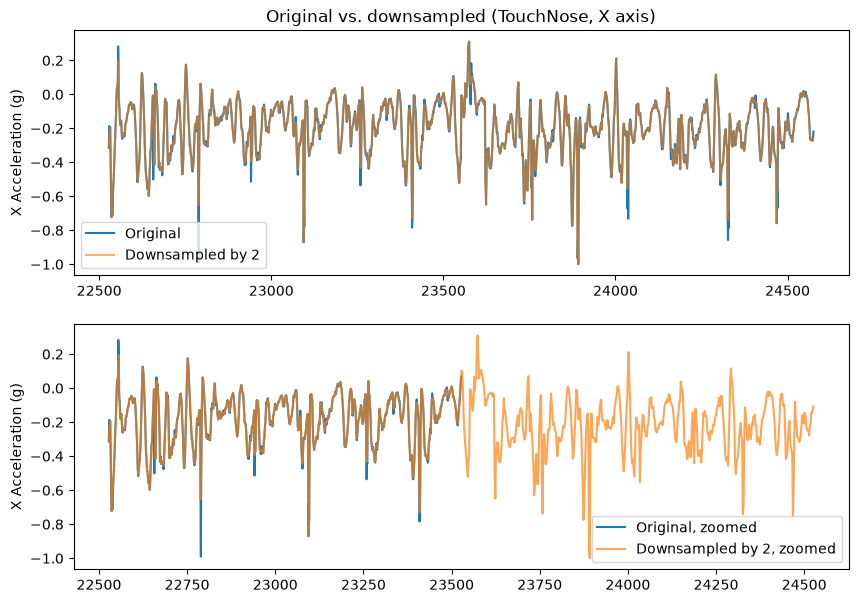

In [85]:
#  EXAMPLE — downsample by 2 and compare
downsampled_data = data.iloc[::2].copy()   # .copy() makes it an independent table

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(data[data['task'] == 'TouchNose']['Acc_X'], label='Original')
ax[0].plot(downsampled_data[downsampled_data['task'] == 'TouchNose']['Acc_X'],
           label='Downsampled by 2', alpha=0.6)
ax[0].set_ylabel('X Acceleration (g)')
ax[0].set_title('Original vs. downsampled (TouchNose, X axis)')
ax[0].legend()

ax[1].plot(data[data['task'] == 'TouchNose']['Acc_X'][0:1000], label='Original, zoomed')
ax[1].plot(downsampled_data[downsampled_data['task'] == 'TouchNose']['Acc_X'][0:1000],
           color='tab:orange', label='Downsampled by 2, zoomed', alpha=0.7)
ax[1].set_ylabel('X Acceleration (g)')
ax[1].legend()
plt.show()

# The two curves lie almost on top of each other here. That works because the original
# row index survives into the downsampled table, so pandas plots each sample at its
# original position.

Remember, the x axis is in samples, so when you plot the first 1000 samples, you will get this plot. This does not mean that the signal has changed lengths.

### Your turn (B.4)

1. Complete the function below so it plots the TouchNose X-axis signal for **several** downsampling factors, each in its own subplot, with the original overlaid. Then run it with `factors = [2, 5, 10, 15]`. Your code should work no matter how many factors are in the list.
2. In one line: downsample the **whole dataset** (`original_data` — all subjects, wrists and tasks) by a factor of 2, into a variable `all_subs_downsampled`.

In [86]:
# YOUR TURN — complete the function

# def downsample_comparison(data, task_name, factors):
#     fig, ax = plt.subplots(len(factors), 1, figsize=(10, 2.5 * len(factors)))
#     for i, factor in enumerate(factors):
#         downsampled = ...
#         ax[i].plot( ... , label='Original')
#         ax[i].plot( ... , label=f'Downsampled by {factor}')
#         ax[i].set_title(f'Downsampling factor: {factor}')
#         ax[i].legend()
#         if i != len(factors) - 1:
#             ax[i].set_xticklabels([])
#     plt.show()

# factors = [2, 5, 10, 15]
# downsample_comparison(data, 'TouchNose', factors)

# all_subs_downsampled = ...

> Downsampling was an exploration — to keep things simple, **we continue with the full-rate (~100 Hz) data** from here on.

## B.5 Filtering the accelerometer signal

###  Concept — which frequencies do we want?

What lives at which frequency in wrist accelerometer data?

- **Below ~1.5 Hz:** gravity and slow changes in wrist orientation — huge in amplitude, but not what we are after.
- **Voluntary movement:** mostly below ~3.5 Hz (reaching, turning the wrist, walking rhythm).
- **Parkinsonian tremor:** rest tremor is typically **4–6 Hz**; tremor during posture/action can reach up to ~12 Hz.

So we will **band-pass between 1.5 and 10 Hz**: remove the dominating gravity/orientation component, keep the dynamics of movement and tremor, and discard faster noise. We can reuse the very same `bandpass_filter` function from Part A — the concept doesn't care whether the signal is a heart or a wrist.

###  Concept — applying a function to every column: `.apply()` and `lambda`

Our filter function works on one array, but we have **three** columns (X, Y, Z). Instead of copy-pasting the call three times, pandas lets us apply a function to each column in one go:

```python
df.apply(function)          # calls function(column) on every column, collects the results
```

Often the function we want to apply needs extra arguments (our filter needs `fs` and the cutoffs). That is where `lambda` comes in — a **mini-function written in one line**, defined right where you need it:

```python
lambda x: x * 2             # a nameless function that doubles its input
```

For example, `df.apply(lambda col: col * 2)` doubles every column. Putting the two together, we can say: *"for every column, run our band-pass filter on it, with these settings"*:

```python
df.apply(lambda col: bandpass_filter(col, fs=fs, low_cutoff=1.5, high_cutoff=10))
```

In [ ]:
#  EXAMPLE — band-pass all three axes of subject 1

# Same function as in Part A. We repeat the definition here in case you restarted
# your kernel (note that it takes fs as an argument - never rely on a value
# "floating around" in the notebook from an earlier section).
from scipy.signal import butter, filtfilt

def bandpass_filter(signal, fs, low_cutoff=0.5, high_cutoff=30, order=4):
    nyquist = 0.5 * fs
    low = low_cutoff / nyquist
    high = high_cutoff / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, signal)

# apply it to each of the three acceleration columns:
bandpassed_data = data[['Acc_X', 'Acc_Y', 'Acc_Z']].apply(
    lambda col: bandpass_filter(col, fs=fs, low_cutoff=1.5, high_cutoff=10, order=4)
)
bandpassed_data

In [89]:
#  EXAMPLE — merge the filtered columns back into our table.
# First rename them (otherwise we would have two columns called 'Acc_X'):
rename_dict = {
    'Acc_X': 'Acc_X_bandpassed',
    'Acc_Y': 'Acc_Y_bandpassed',
    'Acc_Z': 'Acc_Z_bandpassed',
}
bandpassed_data = bandpassed_data.rename(columns=rename_dict)

# then glue the new columns onto the right side of the table (axis=1 = side by side):
data = pd.concat([data, bandpassed_data], axis=1)
data

,t_s,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,subject_id,task,wrist,Acc_X_bandpassed,Acc_Y_bandpassed,Acc_Z_bandpassed
0,0.000000,-0.003958,0.002360,1.746120e-03,-0.015492,0.005616,0.001034,1,Relaxed,LeftWrist,-0.009684,-0.000226,0.000505
1,0.009903,-0.004005,0.002259,8.355394e-04,-0.012276,0.005605,-0.003218,1,Relaxed,LeftWrist,-0.008829,0.000389,-0.000232
2,0.019901,0.000833,0.002225,9.437218e-04,-0.009051,0.002432,-0.002137,1,Relaxed,LeftWrist,-0.007910,0.000991,-0.000911
3,0.029907,-0.000191,0.004109,4.783000e-07,-0.008911,0.002154,-0.000931,1,Relaxed,LeftWrist,-0.007098,0.001540,-0.001472
4,0.039984,0.001769,0.004064,-1.902400e-03,-0.007830,0.000034,0.000145,1,Relaxed,LeftWrist,-0.006626,0.001964,-0.001860
...,...,...,...,...,...,...,...,...,...,...,...,...,...
28667,287.343076,0.011910,-0.000820,7.057069e-03,-0.012770,0.074248,0.002450,1,Entrainment,RightWrist,0.008090,0.001239,-0.004937
28668,287.353145,0.018005,-0.005750,1.680392e-02,-0.010635,0.074210,-0.006043,1,Entrainment,RightWrist,0.009718,0.001902,-0.003012
28669,287.363217,0.012413,-0.008739,2.263230e-02,-0.010595,0.069931,-0.011354,1,Entrainment,RightWrist,0.009155,0.001429,-0.001912
28670,287.373328,0.009851,-0.012696,3.039986e-02,-0.006272,0.063563,-0.017731,1,Entrainment,RightWrist,0.006748,0.000085,-0.001477


> ⚠️ Subject 1's table contains many separate recordings (11 tasks × 2 wrists) glued together, and we just filtered straight across all the joins. A rigorous analysis would filter **each recording separately** — filtering across the joins smears information between neighbouring recordings. We accept this simplification today to keep the code simple; just remember it is a simplification.

### Your turn (B.5)

1. Plot the **original vs. band-passed** signal for the TouchNose task, one subplot per axis (3 subplots, two lines in each — use `label=` and `legend()` so you can tell them apart).
2. Apply the band-pass filter (1.5–10 Hz, order 4) to **the whole dataset** `original_data`, rename the new columns with `rename_dict`, and concatenate them onto `original_data` — exactly like the example did for one subject.

In [ ]:
# YOUR TURN — write your code here

# 1.
# fig, ax = plt.subplots(3, 1, figsize=(10, 7))
# ...

# 2.
# bandpassed_all = ...
# ...
# original_data = ...

####  What do you observe?

The band-passed signal hovers around zero and looks much calmer: the big slow oscillations are gone. Those were "noise" *for our purposes* — the TouchNose task itself requires rotating the hand from facing up to facing down, and that slow rotation (plus gravity moving between the axes) dominated the raw signal. What remains is the faster dynamics of the movement, with far less variance than the original.

## B.6 Windowing (epoching)

###  Concept

Our final preprocessing step is **windowing** (also called *epoching*): chopping the cleaned signal into short, fixed-length segments. We then compute features **per window** rather than for a whole recording. Why?

- Signals change over time (remember: *non-stationary*). One number for a 20-second recording averages away everything interesting; a number per 3-second window lets us track *how* properties evolve.
- Some features are only meaningful over short stretches, because the events they describe are transient.

We will cut **3-second windows with 1.5 seconds (50%) of overlap**: each new window starts halfway through the previous one, so every window shares its first half with its predecessor.

**Why overlap?** Interesting events don't respect window boundaries. Without overlap, a tremor burst falling exactly on a boundary gets split between two windows and could be missed by both. With 50% overlap, every moment of the signal sits comfortably *inside* at least one window. In the picture below, (a) has no overlap and (b) has 50% overlap:

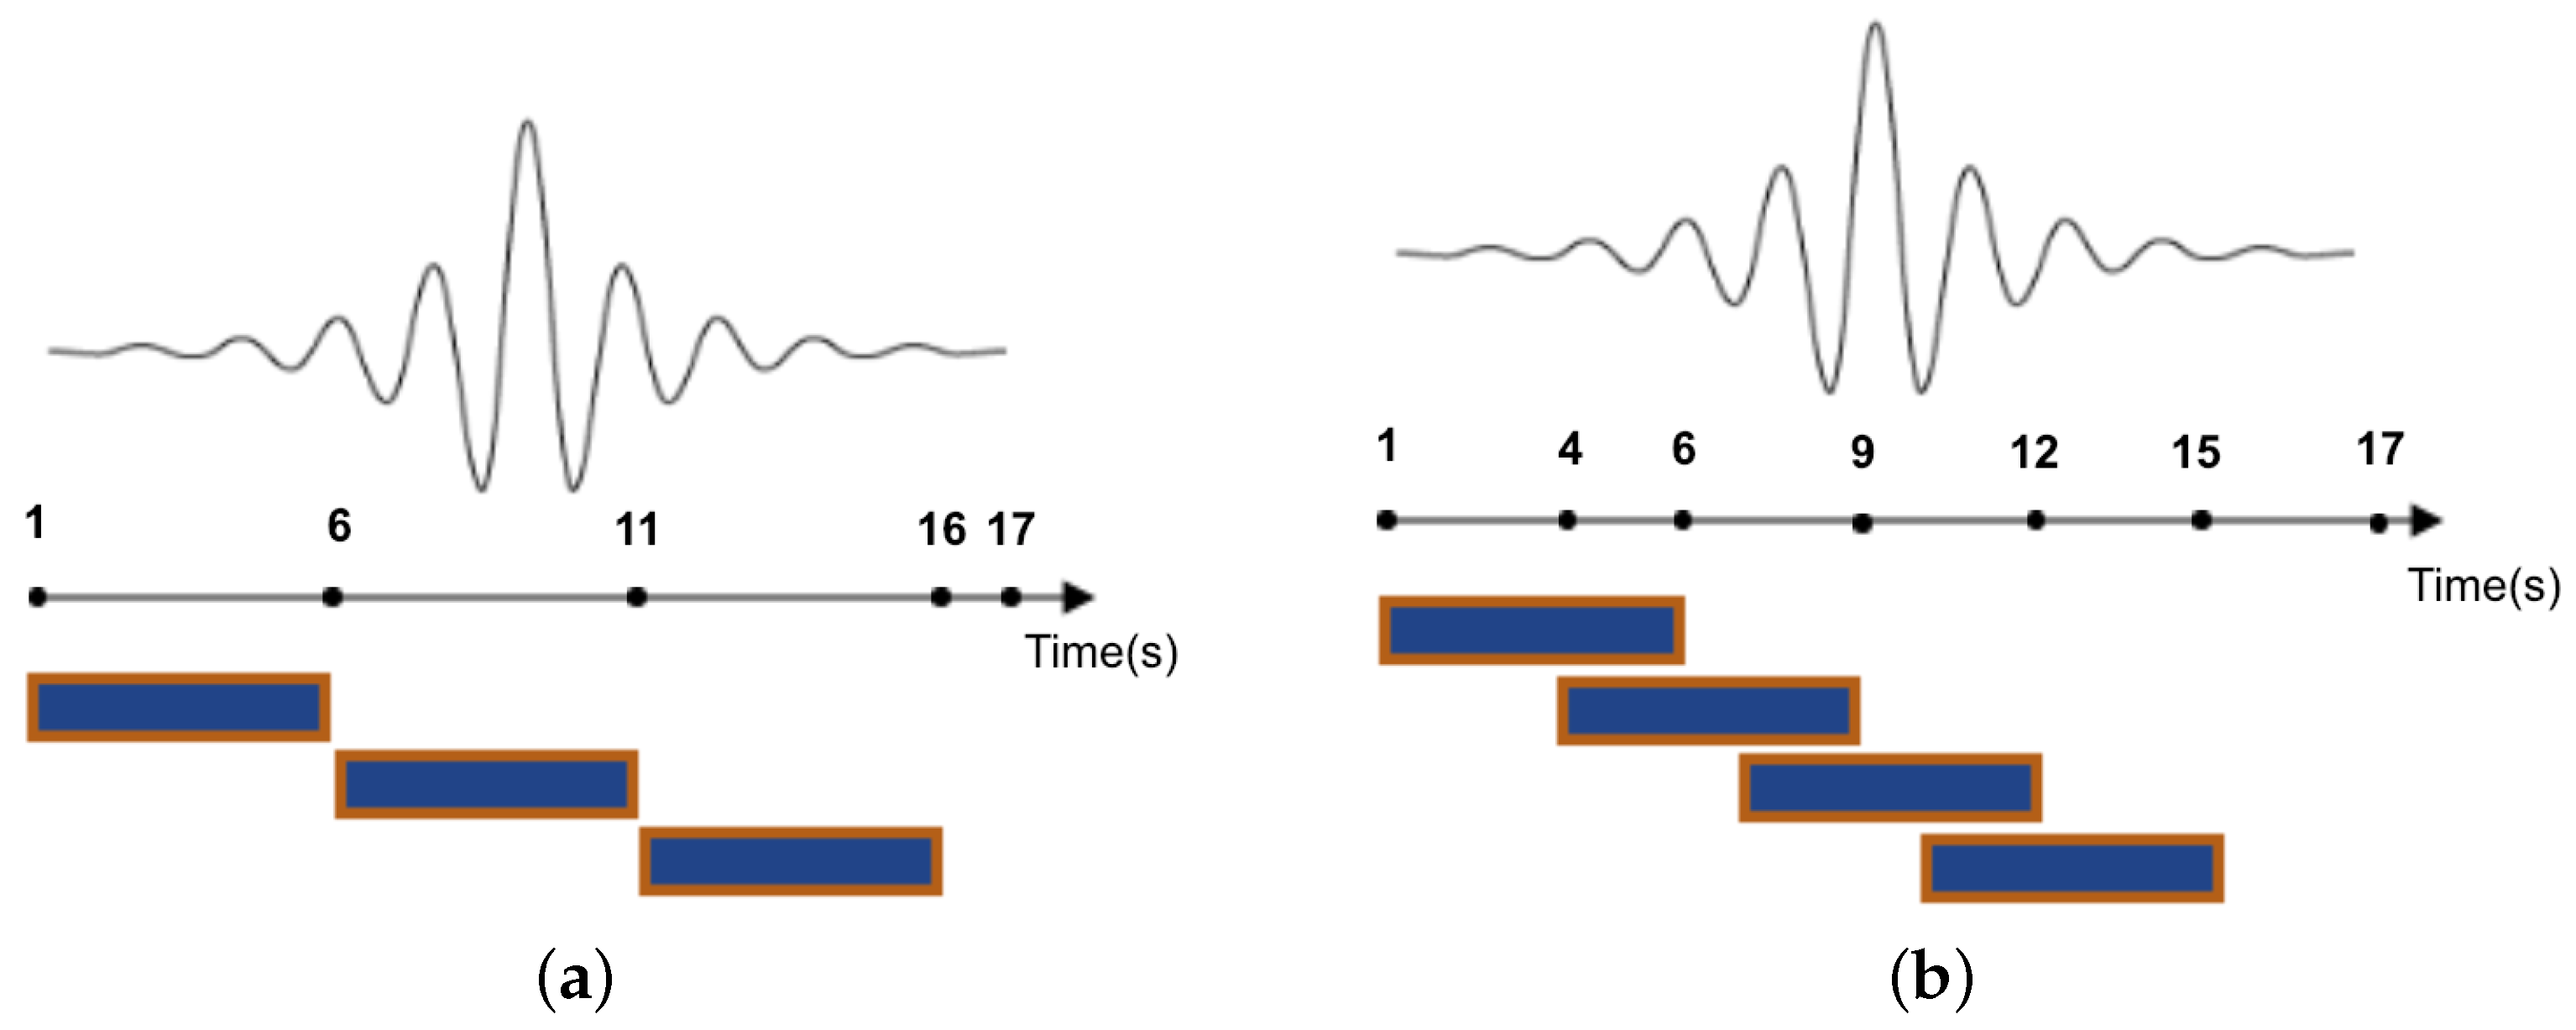

As usual, we first convert times to sample counts: a 3 s window at ~100 Hz contains about 300 samples.

In [91]:
#  EXAMPLE — how many samples per window, and per overlap?
n = int(3 * fs)      # samples in a 3-second window
p = int(1.5 * fs)    # samples in the 1.5-second overlap
print(f'Samples per window:  {n}')
print(f'Samples of overlap:  {p}')

Samples per window:  298
Samples of overlap:  149


In [ ]:
#  EXAMPLE — cutting one recording into windows.
# We'll use subject 1, RightWrist, TouchNose (one continuous recording):

snippet = original_data[(original_data['subject_id'] == 1) &
                        (original_data['wrist'] == 'RightWrist') &
                        (original_data['task'] == 'TouchNose')]

def window_data(data, samples_per_window, overlap_samples):
    # Each new window starts step_size samples after the previous one.
    # With 50% overlap, step_size is half a window.
    step_size = samples_per_window - overlap_samples
    last_possible_start = len(data) - samples_per_window + 1   # don't run off the end

    windows = []
    for start_idx in range(0, int(last_possible_start), int(step_size)):
        end_idx = start_idx + samples_per_window
        window = data.iloc[start_idx:end_idx].copy()   # one slice of the table
        windows.append(window)

    return windows   # a list of small DataFrames

windows = window_data(snippet, samples_per_window=n, overlap_samples=p)
print(f'The recording has {len(snippet)} samples ({len(snippet) / fs:.1f} s)')
print(f'It was cut into {len(windows)} windows of {n} samples each')

### Your turn (B.6)

Suppose we preferred **5-second windows with 40% overlap**.

1. How many **samples** would one window contain? How many samples would the **overlap** be? Compute both (as integers).
2. Use `window_data` to re-window `snippet` with these settings. How many windows do you get?

In [93]:
# YOUR TURN — write your code here

# n_5s = ...
# p_40 = ...
# windows_5s = ...

## B.7 Time-domain features per window

###  Concept

Now we are back on familiar ground: for every window, compute summary statistics — the same ones from A.2, plus a few relatives:

- **variance** — the std, squared (another way to express spread),
- **IQR** (interquartile range) — the distance between the 25th and 75th percentile: the range of the "middle half" of the values. Like the std it measures spread, but it ignores extreme values, so the odd artifact barely moves it,
- **RMS** (root mean square) — $\sqrt{\text{mean}(x^2)}$: a measure of the overall *intensity* of the signal. Squaring makes negative swings count as much as positive ones, so RMS is large whenever the signal is active in either direction — a natural "amount of movement" number for accelerometry.

These are called **time-domain features** because they are computed directly from the signal values over time. We collect them into a DataFrame with **one row per window**.

In [95]:
#  EXAMPLE — basic features for every window

def extract_window_features(windows):
    features = []

    for i, window in enumerate(windows):      # i = window number, window = small DataFrame
        window_features = {'window_id': i}

        for axis in ['Acc_X', 'Acc_Y', 'Acc_Z']:
            axis_data = window[axis]

            window_features[f'{axis}_mean'] = axis_data.mean()
            window_features[f'{axis}_median'] = axis_data.median()
            window_features[f'{axis}_max'] = axis_data.max()
            window_features[f'{axis}_min'] = axis_data.min()

        features.append(window_features)      # one dictionary per window...

    return pd.DataFrame(features)             # ...becomes one row per window

window_features = extract_window_features(windows)
window_features

,window_id,Acc_X_mean,Acc_X_median,Acc_X_max,Acc_X_min,Acc_Y_mean,Acc_Y_median,Acc_Y_max,Acc_Y_min,Acc_Z_mean,Acc_Z_median,Acc_Z_max,Acc_Z_min
0,0,-0.200465,-0.214331,0.311083,-0.736980,0.031271,0.011561,0.733984,-0.707693,-0.064572,-0.079507,0.628688,-0.903358
1,1,-0.250006,-0.231803,0.070487,-0.999864,0.017714,0.031506,1.330764,-0.833104,-0.074592,-0.128199,0.631972,-1.167873
2,2,-0.217507,-0.198691,0.211754,-0.999864,0.007694,0.024240,1.330764,-0.833104,-0.061186,-0.101547,0.631972,-1.167873
3,3,-0.209747,-0.209155,0.211754,-0.732078,0.025777,0.010976,0.762821,-0.522939,-0.063940,-0.087573,0.545101,-0.887093
4,4,-0.222938,-0.217883,0.115908,-0.857190,0.021280,-0.009938,1.048225,-0.485885,-0.045736,-0.075104,0.525467,-1.038304


### Your turn (B.7a)

Write `extract_stats_features(windows)` with exactly the same structure, but computing per axis:

- `std` (pandas: `.std()`),
- `variance` (`.var()`),
- `iqr` (hint: `.quantile(0.75)` gives the 75th percentile),
- `rms` (use the formula above with `np.sqrt` and `np.mean`).

Name the columns `'{axis}_std'`, `'{axis}_variance'`, `'{axis}_iqr'`, `'{axis}_rms'`, and store the result in `stats_features`.

In [96]:
# YOUR TURN — write your code here

# def extract_stats_features(windows):
#     features = []
#     for i, window in enumerate(windows):
#         window_features = {'window_id': i}
#         for axis in ['Acc_X', 'Acc_Y', 'Acc_Z']:
#             axis_data = window[axis]
#             ...
#         features.append(window_features)
#     return pd.DataFrame(features)

# stats_features = ...

### Your turn (B.7b) — the big one

Compute the window features **for all subjects, both wrists and all tasks**, and merge everything into a single DataFrame `all_features`.

*Hints:*
- You need three nested loops: over `original_data['subject_id'].unique()`, over the unique wrists, and over the unique tasks.
- Inside the loops: filter the matching snippet → `window_data` it → run both feature extractors on the windows.
- **Important:** once everything is stacked together you can no longer tell which row came from where — so before stacking, add `subject_id`, `wrist` and `task` columns to the feature DataFrames (assigning a single value to a new column fills the whole column: `df['wrist'] = wrist`).
- Combine the two feature tables of one snippet **side by side** (`pd.concat([...], axis=1)` — they describe the same windows), and stack snippets **on top of each other** (`pd.concat([...], ignore_index=True)`).

In [98]:
# YOUR TURN — write your code here

# all_features = pd.DataFrame()
# for subject in original_data['subject_id'].unique():
#     for wrist in ...:
#         for task in ...:
#             ...

## B.8 FINAL TASK: combined features and a quality check

So far every feature used one axis at a time. Some features combine all three — and then we should also check how our features relate to each other. You will now do three things **on your own**:

1. **Vector magnitude** — the total amount of acceleration, combining x, y and z.
2. **Unit conversion** — from g to m/s².
3. **Correlation analysis** — which of our features carry (nearly) the same information?

---

###  Concept — the signal vector magnitude

The three axes describe one 3D acceleration arrow; the **vector magnitude** is that arrow's *length* (Pythagoras, in 3D):

$$|signal| = \sqrt{x^2 + y^2 + z^2}$$

It answers "how much acceleration overall?", regardless of direction — which also makes it insensitive to how the watch happens to be oriented on the wrist. 

### Your turn (B.8a)

Add a new column `vector_mag` to `original_data` containing the vector magnitude of the three **raw** acceleration axes. *Hint: entire columns can be squared, added and square-rooted just like numpy arrays — no loop needed.*

In [ ]:
# YOUR TURN — write your code here

# original_data['vector_mag'] = ...

### Your turn (B.8b)

Our magnitudes are in **g units**. Scientific reports usually want SI units: metres per second squared. One g is defined as exactly **9.80665 m/s²**. Add a column `vector_mag_ms2` with the magnitude converted to m/s².

In [105]:
# YOUR TURN — write your code here

# original_data['vector_mag_ms2'] = ...

In [ ]:
#  EXAMPLE — the vector magnitude next to the three axes it came from
# (subject 1, RightWrist, TouchNose)

one_recording = original_data[(original_data['task'] == 'TouchNose') &
                              (original_data['subject_id'] == 1) &
                              (original_data['wrist'] == 'RightWrist')]

fig, ax = plt.subplots(2, 1, figsize=(10, 8))
ax[0].plot(one_recording['Acc_X'], label='Acc_X')
ax[0].plot(one_recording['Acc_Y'], label='Acc_Y')
ax[0].plot(one_recording['Acc_Z'], label='Acc_Z')
ax[0].plot(one_recording['vector_mag'], label='Vector magnitude (g)', alpha=0.8, linewidth=4)
ax[0].set_ylabel('Acceleration (g)')
ax[0].set_title('Triaxial signal vs. vector magnitude')
ax[0].legend()

ax[1].plot(one_recording['Acc_X'], label='Acc_X')
ax[1].plot(one_recording['Acc_Y'], label='Acc_Y')
ax[1].plot(one_recording['Acc_Z'], label='Acc_Z')
ax[1].plot(one_recording['vector_mag_ms2'], label='Vector magnitude (m/s2)', alpha=0.8, linewidth=4)
ax[1].set_ylabel('Acceleration (m/s2)')
ax[1].legend()
plt.show()



###  Concept — correlation between features

A **correlation coefficient** measures how strongly two quantities move together, from **−1** (when one goes up, the other goes down) through **0** (unrelated) to **+1** (they rise and fall perfectly together).

Why check this for our features? If two features are correlated at 0.98, they carry essentially the **same information** — keeping both adds complexity to a model without adding knowledge. Feature "quality control" like this is a standard step before any machine learning.

Pandas computes all pairwise correlations in one call: `df.corr()`. Plotted as a colour-coded **heatmap**, patterns jump out immediately.

### Your turn (B.8c)

Build the correlation matrix of your `stats_features` table (from B.7a) and store it in `correlation_matrix`.

*Hint: the matrix should only contain actual features — exclude identification columns like `window_id` (and `subject_id`, `wrist`, `task` if your table has them). One tidy way: build a list of the columns to keep with a list comprehension, then select them before calling `.corr()`.*

In [108]:
# YOUR TURN — write your code here

# feature_columns = ...
# correlation_matrix = ...

In [ ]:
#  EXAMPLE — the matrix as a heatmap.
# NOTE: here we only used the statistical features of ONE recording, for simplicity.
# You have already built all_features for every subject, wrist and task - try
# repeating this with (a selection of) those features!

import seaborn as sns

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.2f')
plt.title('Correlation matrix of statistical features')
plt.tight_layout()
plt.show()

####  What do you observe?

- Why are several features **highly correlated** with each other?
- Which pairs would you expect to be almost perfectly correlated *by construction*? (Look back at how each feature is defined.)
- If you had to keep only one feature per highly-correlated group, which would you keep, and why?

In [ ]:
 
# DISCUSSION NOTES (B.8) 
 
# - std and variance are mathematically locked together (variance = std squared), so
#   within each axis they are almost perfectly correlated: they measure the SAME thing
#   on different scales.


# - std and IQR both measure spread, so they correlate strongly too (though less than
#   perfectly - IQR ignores the extreme values, std does not).


# - For a signal with mean ~0 (like our band-passed data), RMS is almost identical to
#   std, so those pair up as well.


# - Correlations BETWEEN axes (e.g. Acc_X_std vs Acc_Y_std) reflect the movement
#   itself: a vigorous window is vigorous on all axes at once.


# - Rule of thumb for which to keep: prefer the feature that is easiest to interpret
#   and most robust for your data (e.g. keep std, drop variance; keep IQR if your
#   data has outliers/artifacts).


---
## Wrap-up

Today you worked through the complete life cycle of two real biomedical time series:

| Step | ECG (Part A) | Accelerometer (Part B) |
|:---|:---|:---|
| Load & understand timing | PhysioNet download, `fs`, duration | CSV → DataFrame, `fs` from timestamps |
| Inspect | statistics, plots, zooming | `describe`, `value_counts`, filtering, plots |
| Missing data | drop, mean/median, forward fill, rolling | — |
| Clean | smoothing, normalisation, band-pass, resampling | band-pass with `.apply` + `lambda` |
| Segment | — | windows with overlap |
| Extract features | R peaks → RR intervals, heart rate | per-window statistics, vector magnitude |
| Organise & check | one table, many subjects | one table, many windows; correlation check |

Every technique here was a deliberately **simple** version of what signal-processing professionals use — but the *workflow* is exactly the real one, and you will keep refining each step throughout the Master's programme.